# 02 · Feature engineering : de 3,3 millions de tickets à une fiche par client

**Question marketing.** Parmi les clients de la base, lesquels vont racheter en août 2020 ? Pour répondre, un modèle a besoin d'**une ligne par client** qui résume son comportement passé. Ce notebook fabrique cette ligne (le « pourquoi » de chaque famille de variables, puis le « comment »), traite les valeurs manquantes et extrêmes, contrôle la qualité de la table et montre **comment chaque famille se relie au rachat**.

**Ce que le notebook produit** (utilisé par les notebooks 03 à 07) : les tables `features_train` et `features_test` (via `c.save_features`), le dictionnaire des variables `results/02_feature_dictionary.csv`, l'AUC univariée `results/02_univariate_auc.csv`, des figures `figures/02_*.png` et un résumé `results/02_summary.md`.

**Règles du jeu**
- La cible n'est **jamais** utilisée pour fabriquer une variable. Elle sert uniquement à *lire* les graphiques et à l'AUC univariée (exploration descriptive).
- La **même fonction** (`features.build_features`) fabrique les variables du train et du test. Tout ce qui s'apprend sur les données (plafonds des valeurs extrêmes, modalités rares) est calculé sur le **train** puis appliqué tel quel au test.
- Les tables restent « brutes et propres » : pas de standardisation ni de one-hot ici, les modèles linéaires du notebook 03 les font dans leur pipeline.

In [1]:
import time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from scipy.stats import ks_2samp, skew
from sklearn.metrics import roc_auc_score

import common as c
import features as ft

warnings.filterwarnings('ignore')
c.set_style()
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 120)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

FIG_MSG = {}          # message de chaque figure (repris dans results/02_summary.md)
GROUPS = list(dict.fromkeys(ft.SPEC['group']))
GCOL = dict(zip(GROUPS, ['#eb6834', '#2a78d6', '#1baf7a', '#4a3aa7', '#d4a017', '#c2185b', '#00838f', '#6d4c41', '#7b8794', '#8bc34a']))


def md(s):
    display(Markdown(s))


def fr(x, nd=1):
    # nombre au format français (espace fine pour les milliers, virgule décimale)
    return f'{x:,.{nd}f}'.replace(',', ' ').replace('.', ',')


def pc(x, nd=1):
    return fr(100 * x, nd) + ' %'


def nf(x):
    return f'{int(x):,}'.replace(',', '\u202f')


def done(fig, name, title):
    import textwrap
    lines = textwrap.wrap(title, width=int(fig.get_figwidth() * 8.2))
    fig.suptitle('\n'.join(lines), x=0.01, ha='left', fontsize=12.5, fontweight='bold', y=1.0)
    fig.tight_layout(rect=(0, 0, 1, 1 - (0.30 * len(lines) + 0.05) / fig.get_figheight()))
    c.save_fig(fig, name)
    FIG_MSG[name] = title
    plt.show()

## 1. Cadrage : une photo du client au 1er août 2020

On se place au **1er août 2020 (`ref_date`)** et on décrit chaque client **uniquement avec ce qui s'est passé avant** : 12 mois de tickets (août 2019 à juillet 2020). La cible est « a-t-il acheté en août 2020 ? ».

Trois décisions de cadrage, qui découlent des questions du cours sur le scoring (*définir les périodes d'entraînement et de test, la saisonnalité, la profondeur d'historique, la fenêtre de calcul de la cible*) :

1. **Unité d'analyse = le client** (pas le ticket) : tout est agrégé par client.
2. **Fenêtres glissantes relatives à `ref_date`** (7, 14, 30, 60, 90, 180 jours et tout l'historique) : « achète-t-il en ce moment ? » se lit mieux avec des fenêtres courtes, « est-il fidèle ? » avec des fenêtres longues.
3. **Saisonnalité** : on ne dispose que d'un seul mois cible (août) donc le modèle ne peut pas apprendre un effet de saisonnalité ; en revanche on peut décrire si le client **était déjà là en août 2019** (même mois l'an passé).

*Lien avec le cours* : définition de la cible, de la profondeur d'historique et de la saisonnalité (slides 50-52, 82-84).

In [2]:
tk_tr, cl_tr = c.load_clean('train')
tk_te, cl_te = c.load_clean('test')
y_all = c.load_target()

# Garde-fou anti-fuite : aucun ticket à partir de la date de référence
assert tk_tr['ts'].max() < c.REF_DATE and tk_te['ts'].max() < c.REF_DATE
assert tk_tr['ts'].min() >= c.START_DATE

md(f'''
| | Train | Test |
|---|---|---|
| Clients | **{nf(len(cl_tr))}** | **{nf(len(cl_te))}** |
| Tickets (une ligne = un passage en caisse) | {nf(len(tk_tr))} | {nf(len(tk_te))} |
| Premier / dernier ticket | {tk_tr['ts'].min():%d/%m/%Y} / {tk_tr['ts'].max():%d/%m/%Y} | {tk_te['ts'].min():%d/%m/%Y} / {tk_te['ts'].max():%d/%m/%Y} |
| Rachat en août 2020 | **{pc(y_all.mean())}** ({nf(y_all.sum())} clients) | inconnu |

Date de référence : **{c.REF_DATE:%d/%m/%Y}** ; aucun ticket ne la dépasse (contrôle ci-dessus).
''')


| | Train | Test |
|---|---|---|
| Clients | **160 424** | **40 106** |
| Tickets (une ligne = un passage en caisse) | 3 292 994 | 822 894 |
| Premier / dernier ticket | 01/08/2019 / 31/07/2020 | 01/08/2019 / 31/07/2020 |
| Rachat en août 2020 | **7,7 %** (12 392 clients) | inconnu |

Date de référence : **01/08/2020** ; aucun ticket ne la dépasse (contrôle ci-dessus).


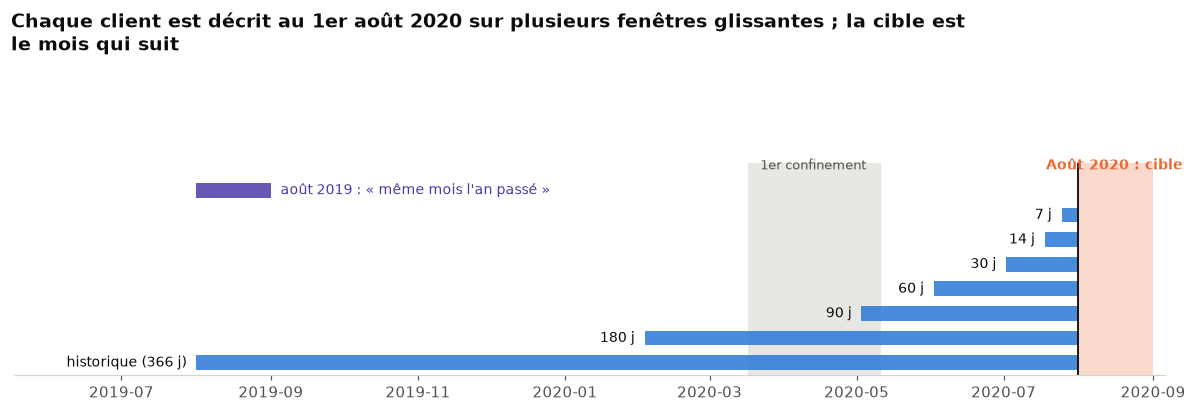

In [3]:
# Schéma des fenêtres d'observation (figure pédagogique)
fig, ax = plt.subplots(figsize=(11, 3.7))
ref, start = c.REF_DATE, c.START_DATE
end_target = ref + pd.DateOffset(months=1)
ax.axvspan(pd.Timestamp('2020-03-17'), pd.Timestamp('2020-05-11'), color=c.GREY, alpha=.35, lw=0)
ax.text(pd.Timestamp('2020-04-13'), 8.35, '1er confinement', ha='center', fontsize=8.5, color=c.INK2)
ax.axvspan(ref, end_target, color=c.ACCENT, alpha=.25, lw=0)
ax.text(ref + pd.Timedelta(days=15), 8.35, 'Août 2020 : cible', ha='center', fontsize=9, color=c.ACCENT, fontweight='bold')
ax.axvline(ref, color=c.INK, lw=1.2)
rows = [('7 j', 7), ('14 j', 14), ('30 j', 30), ('60 j', 60), ('90 j', 90), ('180 j', 180), ('historique (366 j)', 366)]
for i, (lab, w) in enumerate(rows[::-1]):
    y0 = i + 0.5
    ax.barh(y0, pd.Timedelta(days=w), left=ref - pd.Timedelta(days=w), height=.6, color=c.BLUE, alpha=.85)
    ax.text(ref - pd.Timedelta(days=w) - pd.Timedelta(days=4), y0, lab, ha='right', va='center', fontsize=9)
ax.barh(len(rows) + .5, (ref - pd.DateOffset(years=1) + pd.DateOffset(months=1)) - (ref - pd.DateOffset(years=1)),
        left=ref - pd.DateOffset(years=1), height=.6, color=c.PURPLE, alpha=.85)
ax.text(ref - pd.DateOffset(years=1) + pd.DateOffset(months=1) + pd.Timedelta(days=4), len(rows) + .5,
        'août 2019 : « même mois l\'an passé »', va='center', fontsize=9, color=c.PURPLE)
ax.set_xlim(start - pd.Timedelta(days=75), end_target + pd.Timedelta(days=5)); ax.set_ylim(0, 8.6)
ax.set_yticks([]); ax.spines['left'].set_visible(False)
done(fig, '02_fenetres_observation',
     'Chaque client est décrit au 1er août 2020 sur plusieurs fenêtres glissantes ; la cible est le mois qui suit')

## 2. Construction des variables

`features.build_features(tickets, clients, ref_date)` est écrite une seule fois et appliquée au train et au test. Elle est **vectorisée** (aucune boucle sur les clients : tout passe par des `groupby` pandas) et ne garde que les tickets antérieurs à `ref_date`.

Quelques conventions qui comptent :
- **Tickets d'achat vs retours** : un ticket dont le panier est ≤ 0 est un retour/avoir. Les montants, la récence et la fréquence sont calculés sur les **achats** ; les retours sont décrits à part (nombre, part, montant). Sinon un retour « effacerait » une dépense ou ferait passer pour « récent » un client qui ne fait que rapporter un article.
- **Un ticket = un passage en caisse** (les lignes d'un même client et du même instant, par exemple un paiement fractionné, sont déjà fusionnées par `common.py`).
- **Aucune imputation dans la fabrication** : un compte sans achat dans une fenêtre vaut **0** (règle métier : pas d'achat = zéro achat) ; une grandeur **non définie** (par exemple l'intervalle moyen d'un client qui n'a qu'un ticket) reste **`NaN`**, accompagnée d'un indicateur binaire explicite.

In [4]:
ticket_caps = ft.fit_ticket_caps(tk_tr)           # plafonds panier / articles par ticket, appris sur le TRAIN (voir 4.2)
t0 = time.time(); X_tr = ft.build_features(tk_tr, cl_tr, ticket_caps=ticket_caps); t_tr = time.time() - t0
t0 = time.time(); X_te = ft.build_features(tk_te, cl_te, ticket_caps=ticket_caps); t_te = time.time() - t0

# Mêmes colonnes, même ordre ; index = id_client, trié, aligné avec la cible et les plis
assert list(X_tr.columns) == list(X_te.columns) == ft.FEATURE_NAMES
assert X_tr.index.is_unique and X_te.index.is_unique and X_tr.index.is_monotonic_increasing
assert X_tr.index.equals(c.get_folds().index), 'index train différent de celui des plis'
assert set(X_tr.index) == set(y_all.index), 'clients du train différents de ceux de la cible'
assert len(X_te) == 40106, len(X_te)
y = y_all.loc[X_tr.index]
base = y.mean()

tab = (ft.SPEC.groupby('group', sort=False)
       .agg(variables=('type', 'size'), numeriques=('type', lambda s: (s == 'num').sum()),
            binaires=('type', lambda s: (s == 'bin').sum()), categorielles=('type', lambda s: (s == 'cat').sum())))
tab.loc['Total'] = tab.sum()
md(f"**{X_tr.shape[1]} variables brutes** pour {nf(len(X_tr))} clients du train (calcul : {t_tr:.1f} s) et {nf(len(X_te))} clients du test ({t_te:.1f} s) : la même fonction, quelques secondes.")
display(tab.astype(int))

**98 variables brutes** pour 160 424 clients du train (calcul : 2.5 s) et 40 106 clients du test (0.5 s) : la même fonction, quelques secondes.

,variables,numeriques,binaires,categorielles
group,,,,
Récence,4,4,0,0
Fréquence,13,13,0,0
Montant,17,17,0,0
Rythme et tendance,17,14,3,0
Saisonnalité,11,10,1,0
Promotions et retours,10,10,0,0
Paiement,6,6,0,0
Segment de prix,2,0,1,1
Magasins,7,4,2,1


## 3. Famille par famille : pourquoi, et lien avec le rachat

Pour chaque famille : l'intuition marketing (le « pourquoi »), puis un graphique du **taux de rachat selon la variable**, découpée en classes **pour la lecture seulement** (*discrétisation en classes, slide 87* : les modèles, eux, reçoivent la variable continue). La ligne pointillée est le taux de rachat moyen de la base.

In [5]:
D = X_tr.join(y.rename('y'))      # variables brutes + cible : USAGE DESCRIPTIF UNIQUEMENT


def rate_by(x, edges=None, labels=None, q=None, sel=None):
    # Taux de rachat et effectifs par classes (bornes fixes ou quantiles).
    x = x if sel is None else x[sel]
    if q is not None:
        cl = pd.qcut(x, q, duplicates='drop')
        cl = cl.cat.rename_categories([(f'≤{v:,.0f}'.replace(',', '\u202f') if abs(v) >= 1000 else f'≤{v:.3g}') for v in cl.cat.categories.right])
    else:
        cl = pd.cut(x, edges, labels=labels, include_lowest=True)
    return y.loc[x.index].groupby(cl, observed=True).agg(rate='mean', n='size')


def rate_cat(x, order=None, top=None):
    t = y.groupby(x).agg(rate='mean', n='size')
    if top is not None:
        t = t.sort_values('n', ascending=False).head(top)
    return t.loc[order] if order is not None else t.sort_values('rate', ascending=False)


def bar_rate(ax, t, title, color=None, rot=0, first=False, ref=None, show_n=True):
    ref = base if ref is None else ref
    r = t['rate'].to_numpy() * 100
    ax.bar(range(len(t)), r, color=color or c.ACCENT, width=.75)
    ax.axhline(ref * 100, color=c.INK2, ls='--', lw=1, label=(f'moyenne {fr(ref * 100)} %' if ref == base else f'moyenne du groupe {fr(ref * 100)} %'))
    for i, v in enumerate(r):
        ax.text(i, v, fr(v), ha='center', va='bottom', fontsize=8)
    labs = [f"{l}\n({n / 1000:.0f} k)" if n >= 10000 else (f"{l}\n({n / 1000:.1f} k)" if n >= 1000 else f"{l}\n({n})")
            for l, n in zip(t.index.astype(str), t['n'])] if show_n else list(t.index.astype(str))
    ax.set_xticks(range(len(t))); ax.set_xticklabels(labs, fontsize=8, rotation=rot, ha='right' if rot else 'center')
    ax.set_title(title, fontsize=10, loc='left')
    ax.set_ylim(0, max(r.max() * 1.15, ref * 100 * 1.3))
    if first:
        ax.set_ylabel('Taux de rachat en août 2020 (%)')
    ax.legend(fontsize=8, frameon=False, loc='upper left' if r[0] < r.max() / 1.5 else 'upper right')


def grouped_bar(ax, t, title, colors=(c.GREY, c.ACCENT), first=False, ref=None):
    # t : DataFrame index = classes, colonnes = 2 groupes (taux en proportion)
    w = .38
    for j, col in enumerate(t.columns):
        ax.bar(np.arange(len(t)) + (j - .5) * w, t[col] * 100, w, color=colors[j], label=col)
        for i, v in enumerate(t[col] * 100):
            ax.text(i + (j - .5) * w, v, fr(v), ha='center', va='bottom', fontsize=8)
    ax.axhline((base if ref is None else ref) * 100, color=c.INK2, ls='--', lw=1)
    ax.set_xticks(range(len(t))); ax.set_xticklabels(t.index, fontsize=8.5)
    ax.set_title(title, fontsize=10, loc='left'); ax.legend(fontsize=8, frameon=False)
    if first:
        ax.set_ylabel('Taux de rachat en août 2020 (%)')

### 3.1 Récence : « quand est-il venu pour la dernière fois ? »

**Pourquoi.** C'est la variable reine du marketing relationnel (le « R » de RFM) : un client venu hier reviendra bien plus vite qu'un client absent depuis six mois. On la mesure en **jours avant le 1er août** (valeur continue, pour laisser le modèle choisir ses seuils) et on y ajoute l'**avant-dernier achat** et le **dernier intervalle** : deux visites rapprochées en fin d'historique disent plus qu'une visite isolée. L'**ancienneté observée** (premier ticket) distingue les nouveaux clients, qui n'ont pas encore d'historique, des clients installés.

*Lien avec le cours* : RFM, seuils par quantiles ou règles métier (slides 23-28).

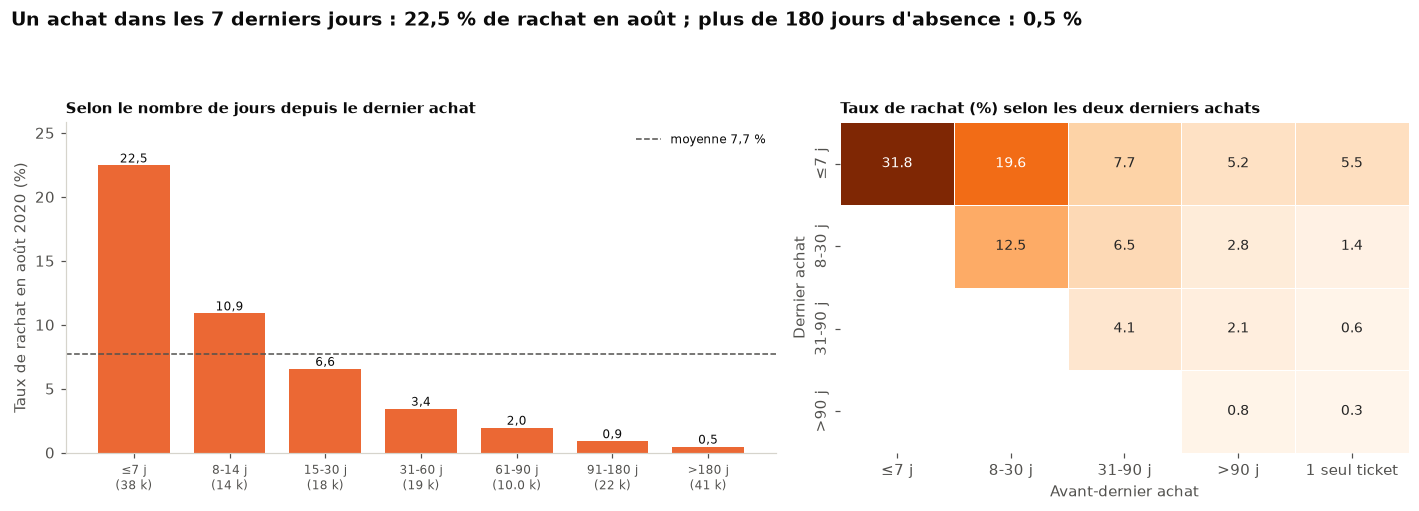

**Lecture.** La récence trie très fortement les clients, mais le dernier achat ne dit pas tout : à récence égale, deux visites rapprochées font monter le taux (colonne « ≤7 j » du second graphique) ; un client qui n'a qu'un seul ticket est quasi toujours un client qui ne reviendra pas. C'est la raison d'être des variables de fréquence et de rythme.

In [6]:
rec = rate_by(D.recency_days, [-.001, 7, 14, 30, 60, 90, 180, 400], ['≤7 j', '8-14 j', '15-30 j', '31-60 j', '61-90 j', '91-180 j', '>180 j'])
last_cl = pd.cut(D.recency_days, [-.001, 7, 30, 90, 400], labels=['≤7 j', '8-30 j', '31-90 j', '>90 j'])
prev_cl = pd.cut(D.recency_prev_days.fillna(999), [-.001, 7, 30, 90, 400, 1000], labels=['≤7 j', '8-30 j', '31-90 j', '>90 j', '1 seul ticket'])
hm = y.groupby([last_cl, prev_cl], observed=False).agg(['mean', 'size'])
hm_rate = hm['mean'].unstack().where(hm['size'].unstack() >= 100)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1.25, 1]})
bar_rate(axs[0], rec, 'Selon le nombre de jours depuis le dernier achat', first=True)
sns.heatmap(hm_rate * 100, annot=True, fmt='.1f', cmap='Oranges', cbar=False, ax=axs[1], linewidths=.5, annot_kws={'fontsize': 9})
axs[1].set_xlabel('Avant-dernier achat'); axs[1].set_ylabel('Dernier achat'); axs[1].set_title('Taux de rachat (%) selon les deux derniers achats', fontsize=10, loc='left')
done(fig, '02_recence_rachat',
     f"Un achat dans les 7 derniers jours : {pc(rec['rate'].iloc[0])} de rachat en août ; plus de 180 jours d'absence : {pc(rec['rate'].iloc[-1])}")
md(f"**Lecture.** La récence trie très fortement les clients, mais le dernier achat ne dit pas tout : à récence égale, deux visites rapprochées font monter le taux (colonne « ≤7 j » du second graphique) ; un client qui n'a qu'un seul ticket est quasi toujours un client qui ne reviendra pas. C'est la raison d'être des variables de fréquence et de rythme.")

### 3.2 Fréquence : « à quelle fréquence vient-il ? »

**Pourquoi.** Le « F » de RFM. On compte les tickets sur **plusieurs fenêtres** (7, 14, 30, 60, 90, 180 jours, tout l'historique) : une fenêtre courte capte l'élan du moment, une fenêtre longue le niveau de fidélité, et leur écart la tendance. On ajoute le nombre de **jours, semaines et mois actifs** (plusieurs tickets le même jour ne sont qu'une visite) et la régularité (part des semaines actives).

*Pourquoi pas une fenêtre de 365 jours ?* L'historique couvre 366 jours : « 365 jours » ≈ « tout l'historique » (variable quasi identique), on garde donc seulement `n_tickets_all`.

*Valeurs manquantes (slide 86).* Un compte sans achat dans la fenêtre est un **0** (règle métier), pas une valeur inconnue : aucune imputation n'est nécessaire.

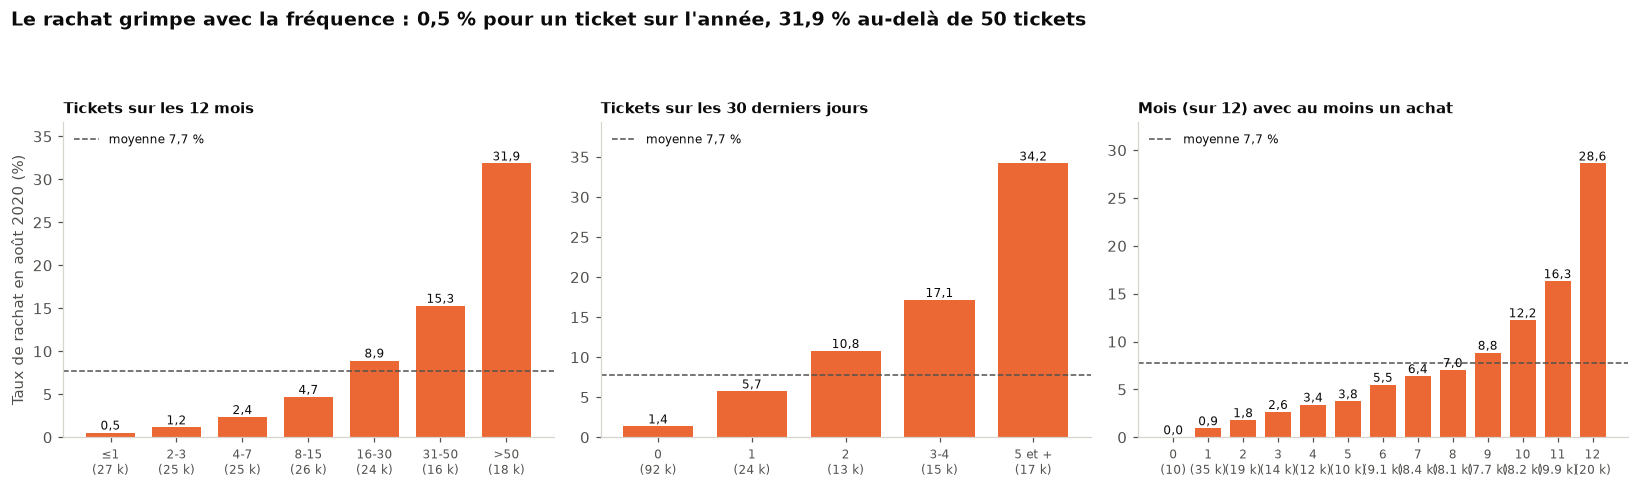

**Lecture.** La fréquence de long terme (1er graphique) et celle du dernier mois (2e) sont toutes deux très discriminantes. Un client sans aucun achat dans les 30 derniers jours rachète 1,4 % du temps contre 34,2 % pour 5 tickets ou plus : la fenêtre courte apporte une information que la fenêtre longue ne donne pas.

In [7]:
f_all = rate_by(D.n_tickets_all, [-.5, 1, 3, 7, 15, 30, 50, 1e5], ['≤1', '2-3', '4-7', '8-15', '16-30', '31-50', '>50'])
f_30 = rate_by(D.n_tickets_30, [-.5, 0, 1, 2, 4, 1e4], ['0', '1', '2', '3-4', '5 et +'])
f_m = y.groupby(D.n_active_months.astype(int)).agg(rate='mean', n='size')
f_m.index = f_m.index.astype(str)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
bar_rate(axs[0], f_all, 'Tickets sur les 12 mois', first=True)
bar_rate(axs[1], f_30, 'Tickets sur les 30 derniers jours')
bar_rate(axs[2], f_m, 'Mois (sur 12) avec au moins un achat')
done(fig, '02_frequence_rachat',
     f"Le rachat grimpe avec la fréquence : {pc(f_all['rate'].iloc[0])} pour un ticket sur l'année, {pc(f_all['rate'].iloc[-1])} au-delà de 50 tickets")
md(f"**Lecture.** La fréquence de long terme (1er graphique) et celle du dernier mois (2e) sont toutes deux très discriminantes. Un client sans aucun achat dans les 30 derniers jours rachète {pc(f_30['rate'].iloc[0])} du temps contre {pc(f_30['rate'].iloc[-1])} pour 5 tickets ou plus : la fenêtre courte apporte une information que la fenêtre longue ne donne pas.")

### 3.3 Montant : « combien dépense-t-il ? » (et la grille RFM)

**Pourquoi.** Le « M » de RFM. La dépense cumulée est un proxy de la **taille du foyer** et de la place qu'occupe l'enseigne dans ses courses ; le panier moyen distingue les « courses du mois » des « achats d'appoint », la dispersion des paniers (médian, maximum, écart-type) le caractère régulier ou exceptionnel des dépenses. Même logique de fenêtres que pour la fréquence. Le **volume d'articles** complète (un panier peut être cher parce qu'il y a beaucoup d'articles ou parce que les articles sont chers : d'où la dépense moyenne par article).

*Lien avec le cours* : RFM et segments actionnables (slides 23-28). La grille ci-dessous croise Récence et Fréquence/Montant par **quintiles** (règle du cours) ; elle ne sert qu'à lire les données, la segmentation proprement dite est faite au notebook 05.

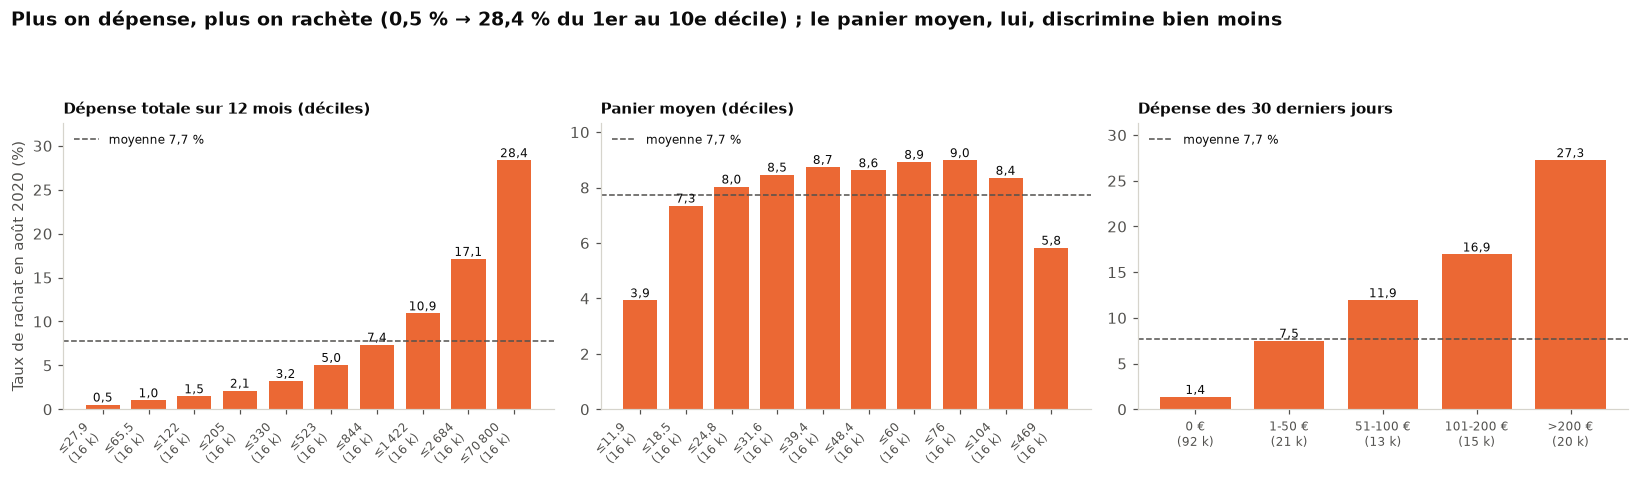

In [8]:
m_all = rate_by(D.spend_all, q=10)
m_bsk = rate_by(D.basket_mean_all, q=10)
m_30 = rate_by(D.spend_30, [-1, 0, 50, 100, 200, 1e7], ['0 €', '1-50 €', '51-100 €', '101-200 €', '>200 €'])

fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
bar_rate(axs[0], m_all, 'Dépense totale sur 12 mois (déciles)', rot=45, first=True)
bar_rate(axs[1], m_bsk, 'Panier moyen (déciles)', rot=45)
bar_rate(axs[2], m_30, 'Dépense des 30 derniers jours')
done(fig, '02_montant_rachat',
     f"Plus on dépense, plus on rachète ({pc(m_all['rate'].iloc[0])} → {pc(m_all['rate'].iloc[-1])} du 1er au 10e décile) ; le panier moyen, lui, discrimine bien moins")

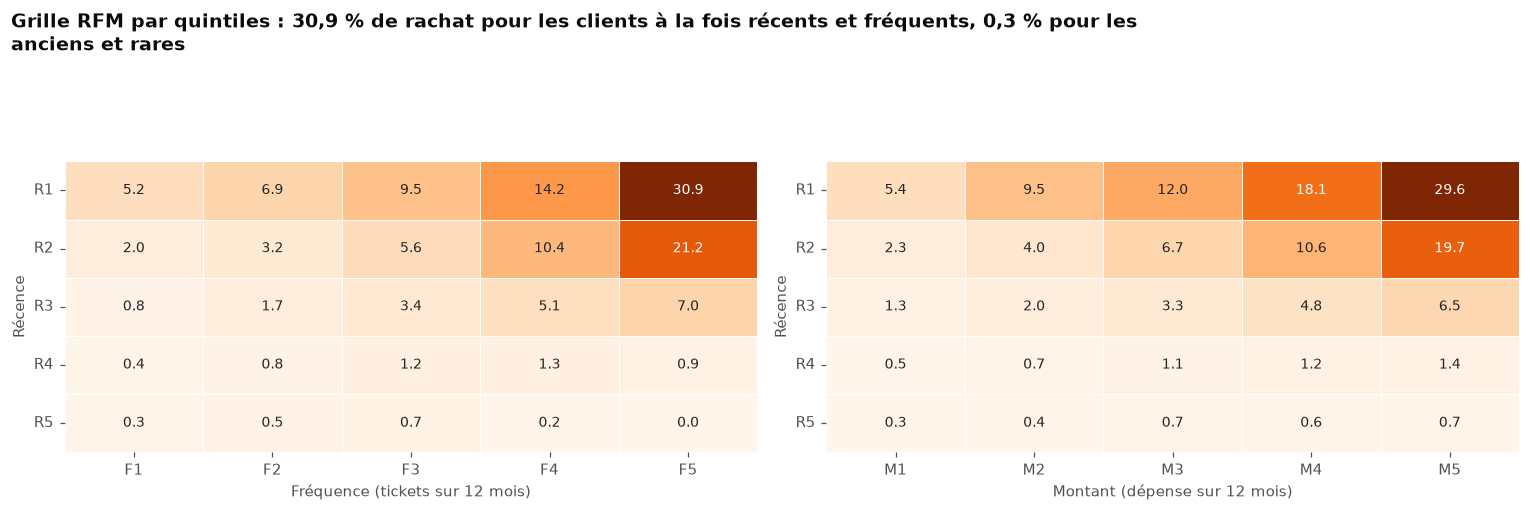

**Lecture.** Les cases en haut à droite (récents et fréquents, ou récents et gros dépensiers) concentrent le rachat ; le coin opposé n'en a presque pas. Les deux axes se **complètent** : à récence égale, la fréquence sépare encore fortement les taux (écart de 25,7 points dans la ligne R1) : un modèle qui ne regarde que la récence perd de l'information.

In [9]:
def quint(x, rev=False):
    q = pd.qcut(x.rank(method='first'), 5, labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
    return q

R5 = pd.qcut(D.recency_days.rank(method='first'), 5, labels=['R1 (le plus récent)', 'R2', 'R3', 'R4', 'R5 (le plus ancien)'])
F5 = pd.qcut(D.n_tickets_all.rank(method='first'), 5, labels=['F1 (le moins fréquent)', 'F2', 'F3', 'F4', 'F5 (le plus fréquent)'])
M5 = pd.qcut(D.spend_all.rank(method='first'), 5, labels=['M1 (le plus faible)', 'M2', 'M3', 'M4', 'M5 (le plus fort)'])
g_rf = (y.groupby([R5, F5], observed=False).mean().unstack() * 100)
g_rm = (y.groupby([R5, M5], observed=False).mean().unstack() * 100)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, g, xl in zip(axs, (g_rf, g_rm), ('Fréquence (tickets sur 12 mois)', 'Montant (dépense sur 12 mois)')):
    sns.heatmap(g, annot=True, fmt='.1f', cmap='Oranges', cbar=False, ax=ax, linewidths=.5, annot_kws={'fontsize': 9})
    ax.set_xlabel(xl); ax.set_ylabel('Récence'); ax.set_xticklabels([t.get_text().split(' ')[0] for t in ax.get_xticklabels()], rotation=0)
    ax.set_yticklabels([t.get_text().split(' ')[0] for t in ax.get_yticklabels()], rotation=0)
done(fig, '02_rfm_grille',
     f"Grille RFM par quintiles : {fr(g_rf.iloc[0, -1])} % de rachat pour les clients à la fois récents et fréquents, {fr(g_rf.iloc[-1, 0])} % pour les anciens et rares")
md(f"**Lecture.** Les cases en haut à droite (récents et fréquents, ou récents et gros dépensiers) concentrent le rachat ; le coin opposé n'en a presque pas. Les deux axes se **complètent** : à récence égale, la fréquence sépare encore fortement les taux (écart de {fr(g_rf.iloc[0, -1] - g_rf.iloc[0, 0])} points dans la ligne R1) : un modèle qui ne regarde que la récence perd de l'information.")

### 3.4 Rythme d'achat et tendance : « est-il en retard sur ses habitudes ? »

**Pourquoi.** Deux clients absents depuis 20 jours ne sont pas dans la même situation s'ils viennent d'habitude toutes les semaines (ils sont **en retard**, peut-être partis) ou tous les deux mois (ils sont **dans leur rythme**). On calcule donc l'intervalle moyen, médian et l'écart-type entre deux tickets, puis le **retard relatif** (récence / intervalle habituel, plancher d'un jour pour éviter les divisions par zéro) et le même retard exprimé en écarts-types (*écart à la moyenne*, slide 85). La **tendance** compare les 90 derniers jours aux 90 précédents (ratio en log) : un client qui accélère ou qui décélère (*segment « Décélération » du cours*, slide 27) n'a pas le même profil qu'un client stable.

*Valeurs manquantes.* L'intervalle n'est **pas défini** pour un client qui n'a qu'un ticket (et l'écart-type pour moins de 3 tickets) : on garde `NaN`, plus honnête que 0, et on ajoute les indicateurs `is_one_shot` et `has_interval_std`. Un client à un ticket n'est pas un client « à rythme nul », c'est un client sans rythme observable.

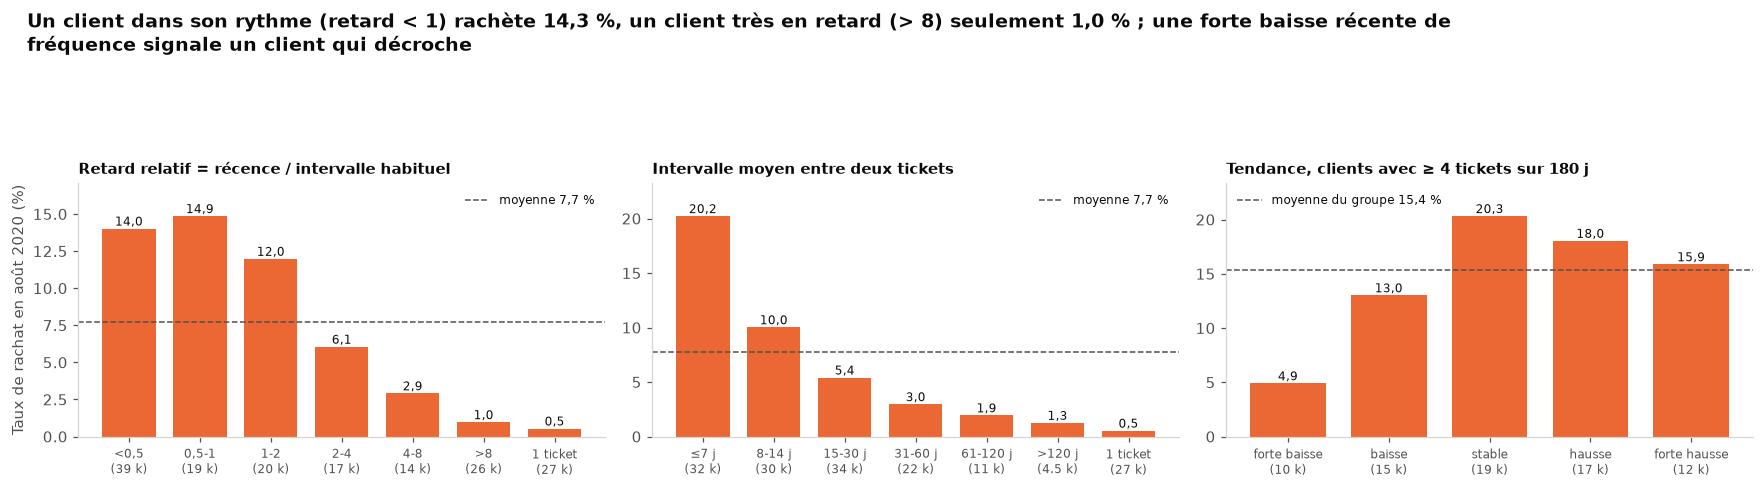

**Lecture.** Le retard relatif apporte ce que la récence seule ne dit pas : le taux de rachat s'effondre quand le client dépasse largement son rythme. Les clients à un seul ticket forment une classe à part (taux de 0,5 %). Parmi les clients assez actifs, une **forte baisse** de fréquence sur 90 jours donne 4,9 % de rachat contre 20,3 % pour un rythme stable ; la relation n'est pas monotone (une forte hausse, souvent un client qui revient, rachète un peu moins qu'un client stable) : un argument de plus pour laisser les modèles à arbres découper eux-mêmes.

In [10]:
dr = pd.cut(D.delay_ratio_mean, [-.001, .5, 1, 2, 4, 8, 1e4], labels=['<0,5', '0,5-1', '1-2', '2-4', '4-8', '>8']).cat.add_categories(['1 ticket']).fillna('1 ticket')
t_dr = y.groupby(dr, observed=True).agg(rate='mean', n='size')
im = pd.cut(D.interval_mean_days, [-.001, 7, 14, 30, 60, 120, 400], labels=['≤7 j', '8-14 j', '15-30 j', '31-60 j', '61-120 j', '>120 j']).cat.add_categories(['1 ticket']).fillna('1 ticket')
t_im = y.groupby(im, observed=True).agg(rate='mean', n='size')
act = D.n_tickets_180 >= 4          # la tendance n'a de sens que pour un client assez actif
tf = pd.cut(D.trend_freq_90[act], [-9, -.7, -.2, .2, .7, 9], labels=['forte baisse', 'baisse', 'stable', 'hausse', 'forte hausse'])
t_tf = y[act].groupby(tf, observed=True).agg(rate='mean', n='size')

fig, axs = plt.subplots(1, 3, figsize=(16, 4.4))
bar_rate(axs[0], t_dr, 'Retard relatif = récence / intervalle habituel', first=True)
bar_rate(axs[1], t_im, 'Intervalle moyen entre deux tickets')
bar_rate(axs[2], t_tf, 'Tendance, clients avec ≥ 4 tickets sur 180 j', ref=y[act].mean())
inrhythm = t_dr['rate'].iloc[:2].mul(t_dr['n'].iloc[:2]).sum() / t_dr['n'].iloc[:2].sum()
done(fig, '02_rythme_tendance_rachat',
     f"Un client dans son rythme (retard < 1) rachète {pc(inrhythm)}, un client très en retard (> 8) seulement {pc(t_dr.loc['>8', 'rate'])} ; une forte baisse récente de fréquence signale un client qui décroche")
md(f"**Lecture.** Le retard relatif apporte ce que la récence seule ne dit pas : le taux de rachat s'effondre quand le client dépasse largement son rythme. Les clients à un seul ticket forment une classe à part (taux de {pc(t_dr.loc['1 ticket', 'rate'])}). Parmi les clients assez actifs, une **forte baisse** de fréquence sur 90 jours donne {pc(t_tf.loc['forte baisse', 'rate'])} de rachat contre {pc(t_tf.loc['stable', 'rate'])} pour un rythme stable ; la relation n'est pas monotone (une forte hausse, souvent un client qui revient, rachète un peu moins qu'un client stable) : un argument de plus pour laisser les modèles à arbres découper eux-mêmes.")

### 3.5 Saisonnalité et moment d'achat : « quand fait-il ses courses ? »

**Pourquoi.** Le cours demande de réfléchir aux **effets de saisonnalité** (slide 50) et d'extraire des dates le jour, la semaine, le mois, le week-end (slide 85). Août est le mois de la cible : un client qui **était déjà actif en août 2019** (même mois l'an passé) a une vie locale qui le garde dans la zone en août. On ajoute la part des achats en juillet (le mois qui précède la cible), en été (juillet-août), sur la période des fêtes (20 décembre-4 janvier) et pendant le **premier confinement** (17 mars-10 mai 2020, creux d'activité visible dans les données). Les habitudes de jour et d'heure (week-end, samedi, matin, soir à partir de 18 h) sont des **proxys du mode de vie** : actif qui fait ses courses après le travail, retraité qui y va le matin.

*Précaution de lecture.* Une part (week-end, soir) vaut 0 ou 100 % pour un client qui n'a qu'un ou deux tickets : sur toute la base, ces variables mélangent mode de vie et fréquence. Les deux derniers graphiques sont donc limités aux **clients réguliers (au moins 8 tickets)**, pour comparer des clients de fréquence comparable.

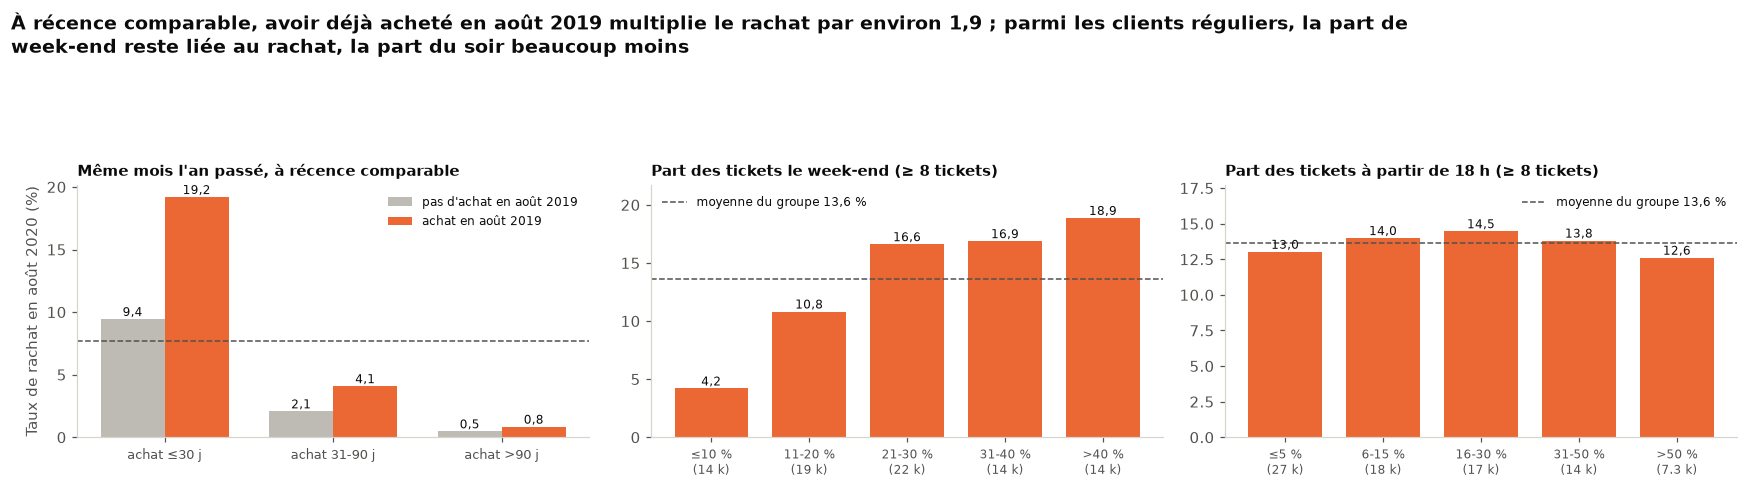

**Lecture.** Pour un dernier achat de moins de 30 jours, 19,2 % de rachat si le client avait acheté en août 2019 contre 9,4 % sinon : l'information « même mois l'an passé » n'est pas réductible à la récence (un client déjà présent en août a une vie locale qui le garde dans la zone ; août 2019 est d'ailleurs le 2e mois en nombre de tickets sur 12, derrière décembre 2019 : ce n'est pas un mois creux dans les données). Parmi les clients réguliers, la part de week-end va de 4,2 % à 18,9 % selon les classes, la part du soir de 12,6 % à 14,5 % : à fréquence comparable, le jour de course (week-end) garde un lien net avec le rachat, l'heure beaucoup moins.

In [11]:
reg8 = D.n_tickets_all >= 8
base8 = y[reg8].mean()
rc = pd.cut(D.recency_days, [-.001, 30, 90, 400], labels=['achat ≤30 j', 'achat 31-90 j', 'achat >90 j'])
sea = (y.groupby([rc, D.bought_same_month_ly.map({0: 'pas d\'achat en août 2019', 1: 'achat en août 2019'})], observed=True).mean().unstack())[['pas d\'achat en août 2019', 'achat en août 2019']]
we = rate_by(D.share_weekend, [-.001, .1, .2, .3, .4, 1], ['≤10 %', '11-20 %', '21-30 %', '31-40 %', '>40 %'], sel=reg8)
ev = rate_by(D.share_evening, [-.001, .05, .15, .3, .5, 1], ['≤5 %', '6-15 %', '16-30 %', '31-50 %', '>50 %'], sel=reg8)

fig, axs = plt.subplots(1, 3, figsize=(16, 4.4))
grouped_bar(axs[0], sea, 'Même mois l\'an passé, à récence comparable', first=True)
bar_rate(axs[1], we, 'Part des tickets le week-end (≥ 8 tickets)', ref=base8)
bar_rate(axs[2], ev, 'Part des tickets à partir de 18 h (≥ 8 tickets)', ref=base8)
ratio = (sea.iloc[:, 1] / sea.iloc[:, 0])
monthly = tk_tr.groupby(tk_tr['ts'].dt.to_period('M')).size().sort_values(ascending=False)
rank_aug19 = list(monthly.index).index(pd.Period('2019-08')) + 1
MOIS = ['janvier', 'février', 'mars', 'avril', 'mai', 'juin', 'juillet', 'août', 'septembre', 'octobre', 'novembre', 'décembre']
done(fig, '02_saisonnalite_rachat',
     f"À récence comparable, avoir déjà acheté en août 2019 multiplie le rachat par environ {fr(ratio.mean())} ; parmi les clients réguliers, la part de week-end reste liée au rachat, la part du soir beaucoup moins")
md(f"**Lecture.** Pour un dernier achat de moins de 30 jours, {pc(sea.iloc[0, 1])} de rachat si le client avait acheté en août 2019 contre {pc(sea.iloc[0, 0])} sinon : l'information « même mois l'an passé » n'est pas réductible à la récence (un client déjà présent en août a une vie locale qui le garde dans la zone ; août 2019 est d'ailleurs le {rank_aug19}{'er' if rank_aug19 == 1 else 'e'} mois en nombre de tickets sur 12, {'derrière ' + MOIS[monthly.index[0].month - 1] + ' ' + str(monthly.index[0].year) if rank_aug19 > 1 else 'devant tous les autres'} : ce n'est pas un mois creux dans les données). Parmi les clients réguliers, la part de week-end va de {pc(we['rate'].min())} à {pc(we['rate'].max())} selon les classes, la part du soir de {pc(ev['rate'].min())} à {pc(ev['rate'].max())} : à fréquence comparable, le jour de course (week-end) garde un lien net avec le rachat, l'heure beaucoup moins.")

### 3.6 Promotions et retours : « est-il sensible aux promotions ? »

**Pourquoi.** La campagne à venir est un **e-mail promotionnel** : savoir si le client achète déjà quand il y a des remises est directement utile (sensibilité au levier). On mesure le **taux de remise** (remises / montant brut), la **part de tickets remisés**, le panier moyen avec et sans remise (une promotion fait-elle grossir le panier ?) et le taux de remise maximal. Les **retours** (panier ≤ 0) sont comptés à part : ils signalent un mécontentement ou un achat exceptionnel, mais restent rares.

*Précaution de lecture.* Plus un client vient souvent, plus il croise de promotions : sur toute la base, la sensibilité aux promotions se confond avec la fréquence. Les graphiques sont donc limités aux **clients réguliers (au moins 8 tickets)** pour comparer des clients de fréquence comparable.

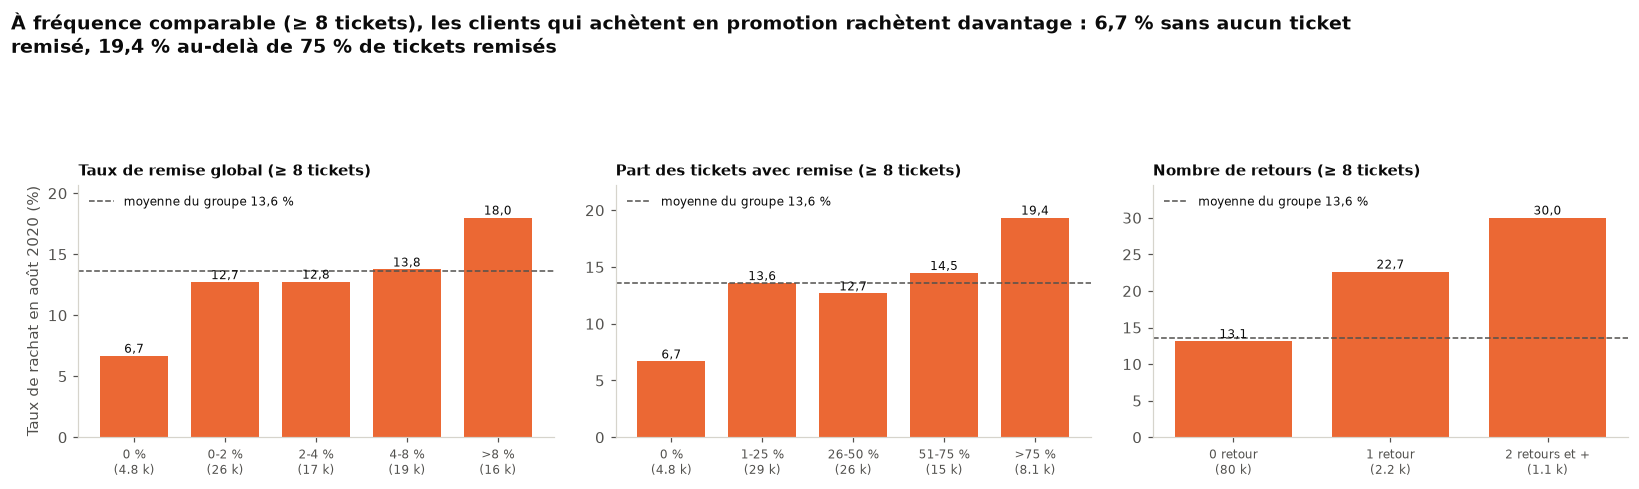

**Lecture.** Même parmi des clients réguliers, la sensibilité aux promotions garde un lien net avec le rachat (6,7 % pour ceux qui n'ont jamais eu de ticket remisé, 19,4 % pour les plus « promotionnels ») : c'est le profil à qui l'e-mail promo parle le plus (à vérifier par test A/B, le lien n'est pas causal). Les retours concernent 2,3 % des clients : variable rare, mais les clients qui font des retours rachètent plus (30,0 % pour 2 retours ou plus parmi les clients réguliers), probablement parce qu'ils achètent beaucoup.

In [12]:
dsc = rate_by(D.discount_rate_all, [-.001, 0, .02, .04, .08, 1], ['0 %', '0-2 %', '2-4 %', '4-8 %', '>8 %'], sel=reg8)
shd = rate_by(D.share_tickets_disc, [-.001, 0, .25, .5, .75, 1], ['0 %', '1-25 %', '26-50 %', '51-75 %', '>75 %'], sel=reg8)
rt = rate_by(D.n_returns, [-.5, 0, 1, 1e4], ['0 retour', '1 retour', '2 retours et +'], sel=reg8)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
bar_rate(axs[0], dsc, 'Taux de remise global (≥ 8 tickets)', first=True, ref=base8)
bar_rate(axs[1], shd, 'Part des tickets avec remise (≥ 8 tickets)', ref=base8)
bar_rate(axs[2], rt, 'Nombre de retours (≥ 8 tickets)', ref=base8)
done(fig, '02_promotions_rachat',
     f"À fréquence comparable (≥ 8 tickets), les clients qui achètent en promotion rachètent davantage : {pc(shd['rate'].iloc[0])} sans aucun ticket remisé, {pc(shd['rate'].iloc[-1])} au-delà de 75 % de tickets remisés")
md(f"**Lecture.** Même parmi des clients réguliers, la sensibilité aux promotions garde un lien net avec le rachat ({pc(shd['rate'].iloc[0])} pour ceux qui n'ont jamais eu de ticket remisé, {pc(shd['rate'].iloc[-1])} pour les plus « promotionnels ») : c'est le profil à qui l'e-mail promo parle le plus (à vérifier par test A/B, le lien n'est pas causal). Les retours concernent {pc((D.n_returns > 0).mean())} des clients : variable rare, mais les clients qui font des retours rachètent plus ({pc(rt['rate'].iloc[-1])} pour 2 retours ou plus parmi les clients réguliers), probablement parce qu'ils achètent beaucoup.")

### 3.7 Mode de paiement : un indice de profil

**Pourquoi.** Le mode de paiement ne se choisit pas au hasard : la carte bancaire domine chez les clients très actifs, les espèces et les chèques ramènent à des profils d'achat d'appoint ou plus âgés, les **cartes cadeaux** signalent un client qui reçoit des avantages de l'enseigne (comité d'entreprise, offres), un paiement mixte un panier plus complexe. On calcule la **part des tickets** payés (au moins en partie) avec chaque mode, la part de tickets à plusieurs modes de paiement et la part sans mode renseigné.

*Précaution de lecture.* On compare les clients dont le mode représente au moins 25 % des tickets aux autres, d'abord sur toute la base, puis parmi les clients réguliers (≥ 8 tickets) pour neutraliser la fréquence.

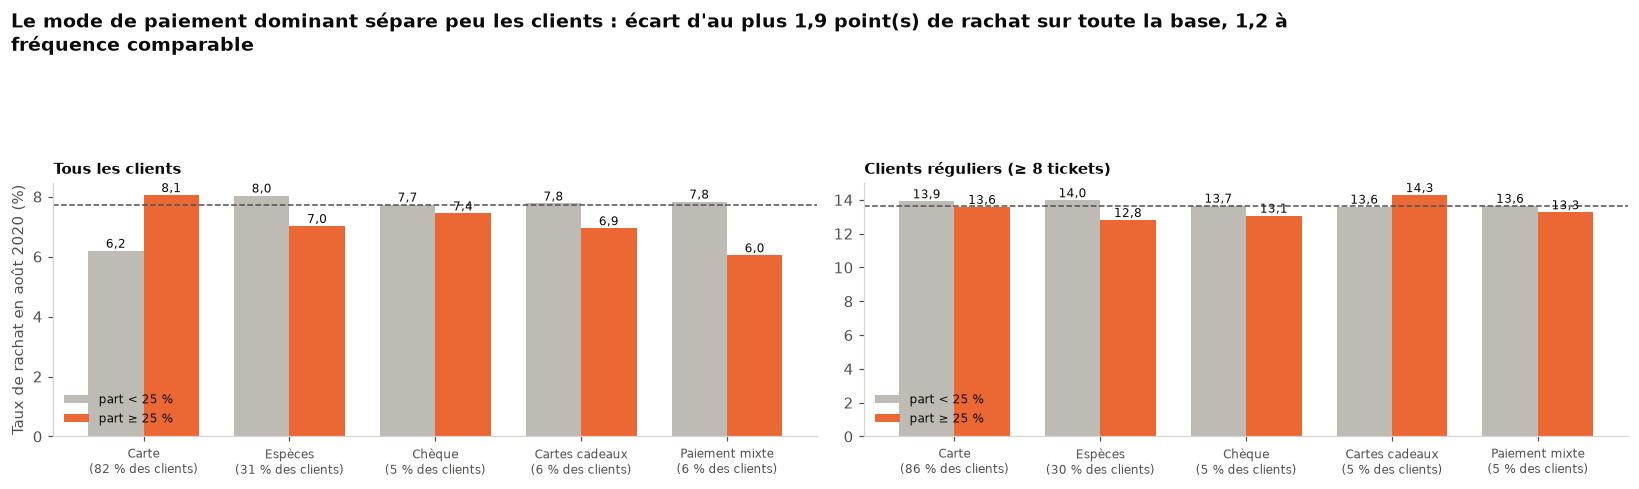

**Lecture.** Le mode de paiement dominant ne discrimine presque pas le rachat (écart maximal de 1,9 point(s) sur toute la base et de 1,2 point(s) parmi les clients réguliers, pour un taux moyen de 7,7 % et 13,6 % respectivement). La famille est conservée (peu coûteuse, utile pour décrire le profil, parfois en interaction avec d'autres variables), mais on s'attend à ce qu'elle pèse peu dans les modèles : la section 7 le confirme avec l'AUC univariée.

In [13]:
modes = [('Carte', 'share_pay_card'), ('Espèces', 'share_pay_cash'), ('Chèque', 'share_pay_cheque'), ('Cartes cadeaux', 'share_pay_gift'), ('Paiement mixte', 'share_pay_mixed')]


def pay_table(mask):
    out = {}
    for lab, col in modes:
        hi = (D[col] >= .25) & mask
        out[f'{lab}\n({pc(hi.sum() / mask.sum(), 0)} des clients)'] = {'part < 25 %': y[mask & ~(D[col] >= .25)].mean(), 'part ≥ 25 %': y[hi].mean()}
    return pd.DataFrame(out).T


pay_all, pay_reg = pay_table(pd.Series(True, index=D.index)), pay_table(reg8)
fig, axs = plt.subplots(1, 2, figsize=(15, 4.4))
grouped_bar(axs[0], pay_all, 'Tous les clients', first=True)
grouped_bar(axs[1], pay_reg, 'Clients réguliers (≥ 8 tickets)', ref=base8)
for ax in axs:
    ax.tick_params(axis='x', labelsize=8)
gap_all = (pay_all['part ≥ 25 %'] - pay_all['part < 25 %']).abs().max() * 100
gap_reg = (pay_reg['part ≥ 25 %'] - pay_reg['part < 25 %']).abs().max() * 100
done(fig, '02_paiement_rachat',
     f"Le mode de paiement dominant sépare peu les clients : écart d'au plus {fr(gap_all, 1)} point(s) de rachat sur toute la base, {fr(gap_reg, 1)} à fréquence comparable")
md(f"**Lecture.** Le mode de paiement dominant ne discrimine presque pas le rachat (écart maximal de {fr(gap_all, 1)} point(s) sur toute la base et de {fr(gap_reg, 1)} point(s) parmi les clients réguliers, pour un taux moyen de {pc(base)} et {pc(base8)} respectivement). La famille est conservée (peu coûteuse, utile pour décrire le profil, parfois en interaction avec d'autres variables), mais on s'attend à ce qu'elle pèse peu dans les modèles : la section 7 le confirme avec l'AUC univariée.")

### 3.8 Segment de prix : sensibilité au prix et à la gamme

**Pourquoi.** `price_segmentation` décrit la gamme des produits (Access = abordable, Mixte, Quali = haut de gamme, xx = produits trop différents pour être classés) : un client haut de gamme n'a pas la même sensibilité au prix ni à la promotion qu'un client « abordable ». **Constat sur les données** (contrôle ci-dessous) : la colonne ne change jamais au sein d'un client, c'est donc un **attribut du client** et non du ticket ; on en fait une seule variable qualitative, `price_segment`, plutôt que des parts de tickets.

**Manquants (slide 86).** Le segment est absent pour une grande part des clients. Plutôt que de supprimer ces clients ou d'inventer une valeur, on garde le manquant comme une **modalité à part (« INCONNU »)** et on ajoute un indicateur binaire : on ne sait pas si le manquant est aléatoire. Le segment `8` (quelques dizaines de lignes seulement) est fusionné dans `xx` (« produits de gammes différentes » : même sens).

**Contrôle** : 100,0 % des clients du train ont une seule valeur de `price_segmentation` (manquant compris) sur l'ensemble de leurs tickets ; le segment est absent pour 56,7 % des clients.

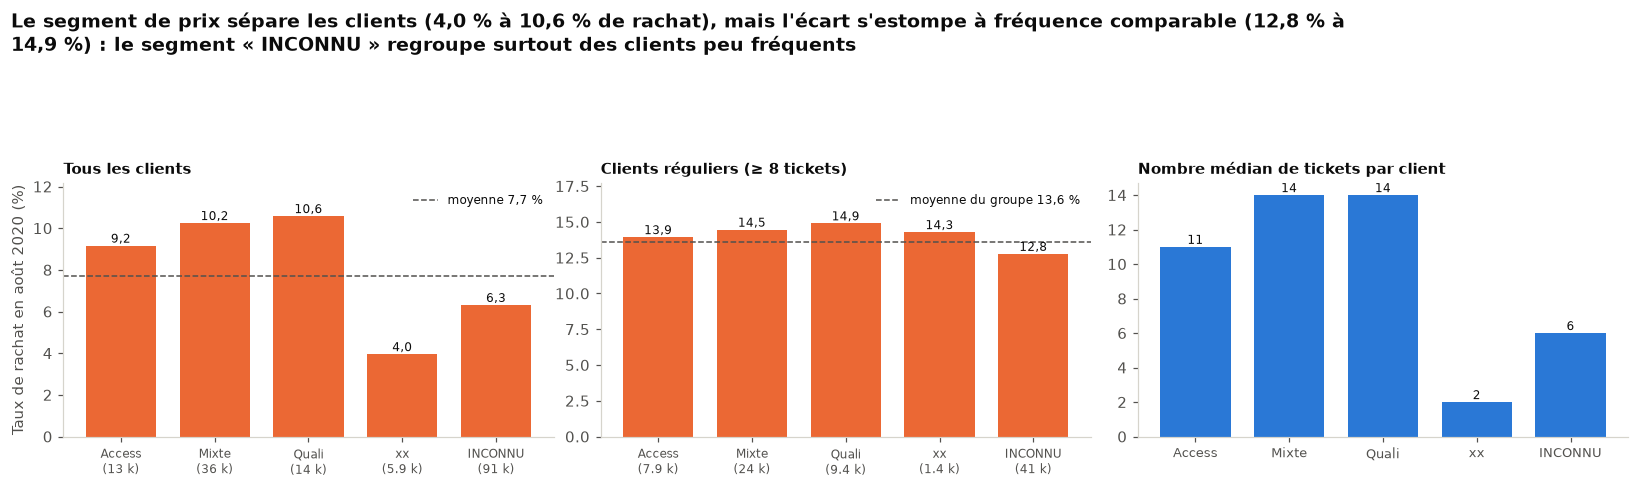

**Lecture.** Les clients sans segment (INCONNU) rachètent 6,3 % contre 10,2 % pour les « Mixte », mais ils font aussi nettement moins de tickets (médiane de 6 contre 14). À fréquence comparable l'écart se réduit à 1,7 point(s) : le manquant reste une modalité utile mais l'essentiel de son effet passe par la fréquence.

In [14]:
nseg = tk_tr.groupby('id_client')['price_segmentation'].nunique(dropna=False)
md(f"**Contrôle** : {pc((nseg == 1).mean())} des clients du train ont une seule valeur de `price_segmentation` (manquant compris) sur l'ensemble de leurs tickets ; le segment est absent pour {pc(D.price_segment_missing.mean())} des clients.")

order = ['Access', 'Mixte', 'Quali', 'xx', 'INCONNU']
sd = rate_cat(D.price_segment, order=order)
sd8 = y[reg8].groupby(D.price_segment[reg8]).agg(rate='mean', n='size').loc[order]
med = D.groupby('price_segment')['n_tickets_all'].median().loc[order]

fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
bar_rate(axs[0], sd, 'Tous les clients', first=True)
bar_rate(axs[1], sd8, 'Clients réguliers (≥ 8 tickets)', ref=base8)
axs[2].bar(range(len(med)), med.values, color=c.BLUE, width=.75)
for i, v in enumerate(med.values):
    axs[2].text(i, v, fr(v, 0), ha='center', va='bottom', fontsize=8)
axs[2].set_xticks(range(len(med))); axs[2].set_xticklabels(order, fontsize=8.5)
axs[2].set_title('Nombre médian de tickets par client', fontsize=10, loc='left')
done(fig, '02_segment_prix_rachat',
     f"Le segment de prix sépare les clients ({pc(sd['rate'].min())} à {pc(sd['rate'].max())} de rachat), mais l'écart s'estompe à fréquence comparable ({pc(sd8['rate'].min())} à {pc(sd8['rate'].max())}) : le segment « INCONNU » regroupe surtout des clients peu fréquents")
md(f"**Lecture.** Les clients sans segment (INCONNU) rachètent {pc(sd.loc['INCONNU', 'rate'])} contre {pc(sd.loc['Mixte', 'rate'])} pour les « Mixte », mais ils font aussi nettement moins de tickets (médiane de {fr(med['INCONNU'], 0)} contre {fr(med['Mixte'], 0)}). À fréquence comparable l'écart se réduit à {fr(100 * (sd8.loc['Mixte', 'rate'] - sd8.loc['INCONNU', 'rate']))} point(s) : le manquant reste une modalité utile mais l'essentiel de son effet passe par la fréquence.")

### 3.9 Magasins : attache locale et mobilité

**Pourquoi.** Le client est-il attaché à **un** magasin (courses de proximité) ou en fréquente plusieurs (mobilité, vacances) ? On décrit le nombre de magasins distincts, la part du **magasin principal**, sa **région** (les deux premiers chiffres du code magasin ; les trois derniers ne sont pas un code postal), le fait que ce magasin soit **hors du département du domicile** (client de passage, résidence secondaire) et le fait que le dernier achat ait eu lieu dans le magasin principal. On ajoute la **fréquentation du magasin principal** : la part des clients de la base qui y ont acheté. C'est une part (et non un effectif) car le test est un échantillon de 20 % : un effectif ne serait pas comparable entre train et test. **La cible n'est pas utilisée.**

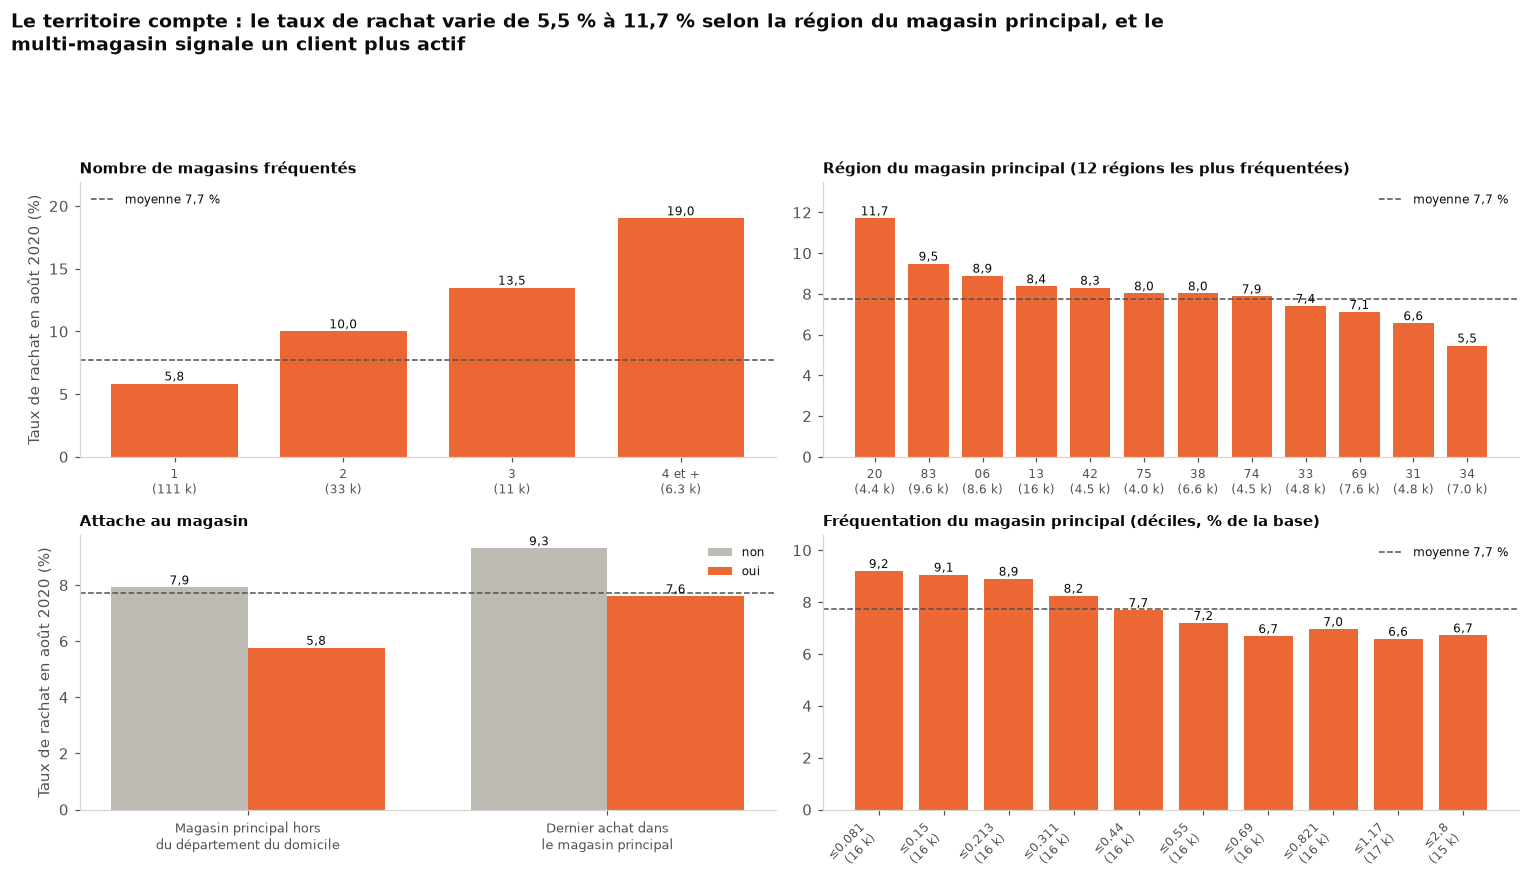

In [15]:
ns = rate_by(D.n_stores.clip(upper=4), [.5, 1.5, 2.5, 3.5, 4.5], ['1', '2', '3', '4 et +'])
reg = rate_cat(D.main_store_region, top=12)
away = pd.DataFrame({'non': {'Magasin principal hors du département du domicile': y[D.main_store_outside_home_dept == 0].mean(),
                             'Dernier achat dans le magasin principal': y[D.last_store_is_main == 0].mean()},
                     'oui': {'Magasin principal hors du département du domicile': y[D.main_store_outside_home_dept == 1].mean(),
                             'Dernier achat dans le magasin principal': y[D.last_store_is_main == 1].mean()}})
away.index = ['Magasin principal hors\ndu département du domicile', 'Dernier achat dans\nle magasin principal']
traf = rate_by(D.main_store_client_share, q=10)

fig, axs = plt.subplots(2, 2, figsize=(14, 8))
bar_rate(axs[0, 0], ns, 'Nombre de magasins fréquentés', first=True)
bar_rate(axs[0, 1], reg, 'Région du magasin principal (12 régions les plus fréquentées)', rot=0)
grouped_bar(axs[1, 0], away, 'Attache au magasin', first=True)
bar_rate(axs[1, 1], traf, 'Fréquentation du magasin principal (déciles, % de la base)', rot=45)
done(fig, '02_magasins_rachat',
     f"Le territoire compte : le taux de rachat varie de {pc(reg['rate'].min())} à {pc(reg['rate'].max())} selon la région du magasin principal, et le multi-magasin signale un client plus actif")

### 3.10 Profil client : qui est-il ?

**Pourquoi.** Les attributs déclarés complètent le comportement : **civilité**, **e-mail renseigné** (les clients sans e-mail sont injoignables par e-mail : à garder en tête pour le ciblage), **domaine de l'e-mail** (le cours le cite comme proxy d'âge : `wanadoo`, `orange`, `laposte` sont des anciens fournisseurs d'accès, `gmail` un webmail récent ; on regroupe en trois types : FAI, webmail, professionnel/autre), **département du domicile**, **carte de fidélité** (indicateur et ancienneté), **multicard** et **profil anonyme** (civilité et multicard absents : le brief indique un taux de rachat quasi nul).

**Traitements de variables qualitatives (slides 86-87).** Les domaines d'e-mail (plusieurs milliers de valeurs) et les départements sont des variables à **très nombreuses modalités** : on regroupe les rares (domaines de moins de 100 clients, départements et régions de magasin de moins de 1 % des clients) dans `AUTRE` (on garde `ETR` pour les codes postaux étrangers), avec une liste apprise **sur le train** et appliquée au test (section 4). Le manquant est une modalité à part (`SANS_EMAIL`, `INCONNU`, `ND`) plus un indicateur binaire explicite (`dept_missing`, `anonymous`).

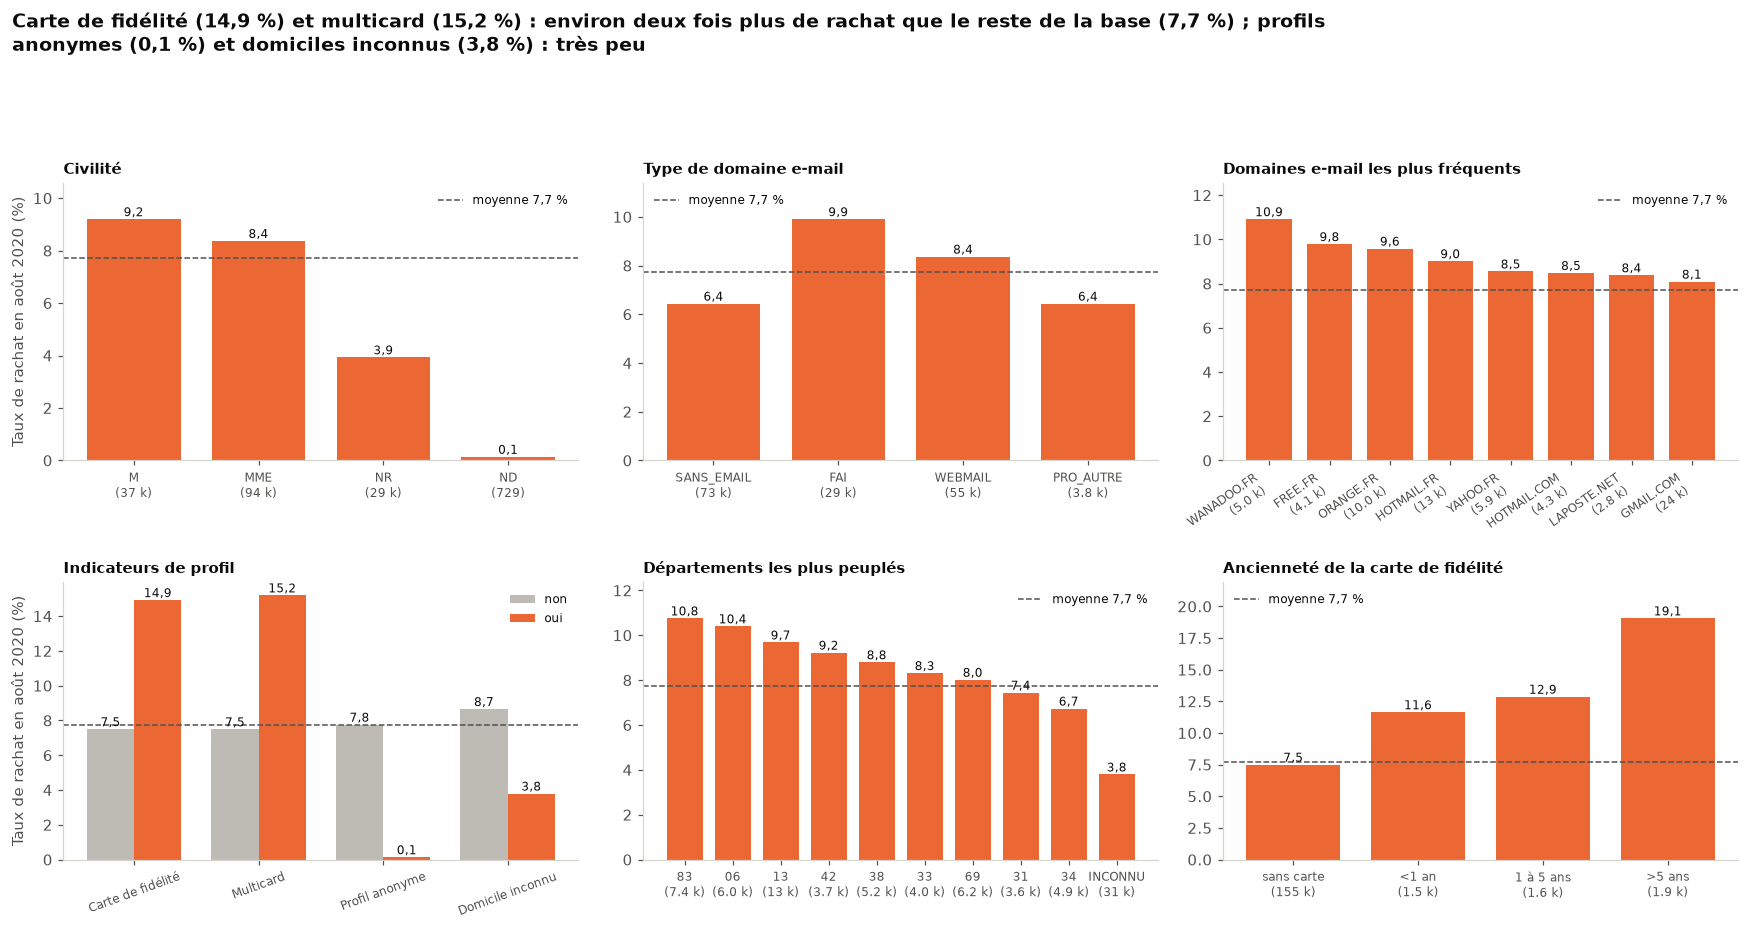

**Lecture.** Les attributs déclarés séparent nettement moins les clients que le comportement (voir l'AUC univariée de la section 7), mais certains sont très marqués : la carte de fidélité et la multicard (engagement), la civilité non renseignée (NR : 3,9 %) et surtout les **profils anonymes** (729 clients, 0,1 % de rachat) qu'on peut exclure du ciblage sans perte. Les clients sans e-mail rachètent 6,4 % contre 8,8 % avec e-mail ; ils sont aussi injoignables par e-mail (45 % de la base), une contrainte pour la campagne.

In [16]:
civ = rate_cat(D.civility, order=['M', 'MME', 'NR', 'ND'])
etype = rate_cat(D.email_type, order=['SANS_EMAIL', 'FAI', 'WEBMAIL', 'PRO_AUTRE'])
dom = rate_cat(D.email_domain.where(D.email_domain != 'SANS_EMAIL'), top=8)
dept_t = rate_cat(D.dept, top=10)
flags = pd.DataFrame({'non': {'Carte de fidélité': y[D.has_card == 0].mean(), 'Multicard': y[D.multicard == 0].mean(), 'Profil anonyme': y[D.anonymous == 0].mean(), 'Domicile inconnu': y[D.dept_missing == 0].mean()},
                      'oui': {'Carte de fidélité': y[D.has_card == 1].mean(), 'Multicard': y[D.multicard == 1].mean(), 'Profil anonyme': y[D.anonymous == 1].mean(), 'Domicile inconnu': y[D.dept_missing == 1].mean()}})
card_t = rate_by(D.card_tenure_days.fillna(-1), [-1.5, -.5, 365, 1825, 1e5], ['sans carte', '<1 an', '1 à 5 ans', '>5 ans'])

fig, axs = plt.subplots(2, 3, figsize=(16, 8.4))
bar_rate(axs[0, 0], civ, 'Civilité', first=True)
bar_rate(axs[0, 1], etype, 'Type de domaine e-mail')
bar_rate(axs[0, 2], dom, 'Domaines e-mail les plus fréquents', rot=35)
grouped_bar(axs[1, 0], flags, 'Indicateurs de profil', first=True)
axs[1, 0].set_xticklabels(flags.index, fontsize=8, rotation=20)
bar_rate(axs[1, 1], dept_t, 'Départements les plus peuplés', rot=0)
bar_rate(axs[1, 2], card_t, 'Ancienneté de la carte de fidélité')
done(fig, '02_profil_rachat',
     f"Carte de fidélité ({pc(flags.loc['Carte de fidélité', 'oui'])}) et multicard ({pc(flags.loc['Multicard', 'oui'])}) : environ deux fois plus de rachat que le reste de la base ({pc(base)}) ; profils anonymes ({pc(flags.loc['Profil anonyme', 'oui'])}) et domiciles inconnus ({pc(flags.loc['Domicile inconnu', 'oui'])}) : très peu")
md(f"**Lecture.** Les attributs déclarés séparent nettement moins les clients que le comportement (voir l'AUC univariée de la section 7), mais certains sont très marqués : la carte de fidélité et la multicard (engagement), la civilité non renseignée (NR : {pc(civ.loc['NR', 'rate'])}) et surtout les **profils anonymes** ({nf((D.anonymous == 1).sum())} clients, {pc(flags.loc['Profil anonyme', 'oui'])} de rachat) qu'on peut exclure du ciblage sans perte. Les clients sans e-mail rachètent {pc(etype.loc['SANS_EMAIL', 'rate'])} contre {pc(D.loc[D.has_email == 1, 'y'].mean())} avec e-mail ; ils sont aussi injoignables par e-mail ({pc(1 - D.has_email.mean(), 0)} de la base), une contrainte pour la campagne.")

## 4. Préparation : manquants, valeurs extrêmes, modalités rares, transformations

C'est le critère de notation n° 1 : on documente chaque traitement et on le justifie. **Tout ce qui s'apprend sur les données (plafonds, modalités gardées, variables transformées en log) est appris sur le train, puis appliqué tel quel au test.**

*Lien avec le cours* : qualité des données, valeurs manquantes, valeurs extrêmes et aberrantes (slide 86) ; discrétisation, regroupement, log (slide 87).

### 4.1 Valeurs manquantes

,part de NaN,NaN exactement quand,écarts
variable,,,
recency_days,0.0%,n_tickets_all = 0,0
interval_mean_days,16.7%,is_one_shot,0
interval_median_days,16.7%,is_one_shot,0
recency_prev_days,16.7%,is_one_shot,0
last_interval_days,16.7%,is_one_shot,0
delay_ratio_mean,16.7%,is_one_shot,0
interval_std_days,25.8%,has_interval_std,0
interval_cv,26.0%,has_interval_std,203
delay_z,25.8%,has_interval_std,0


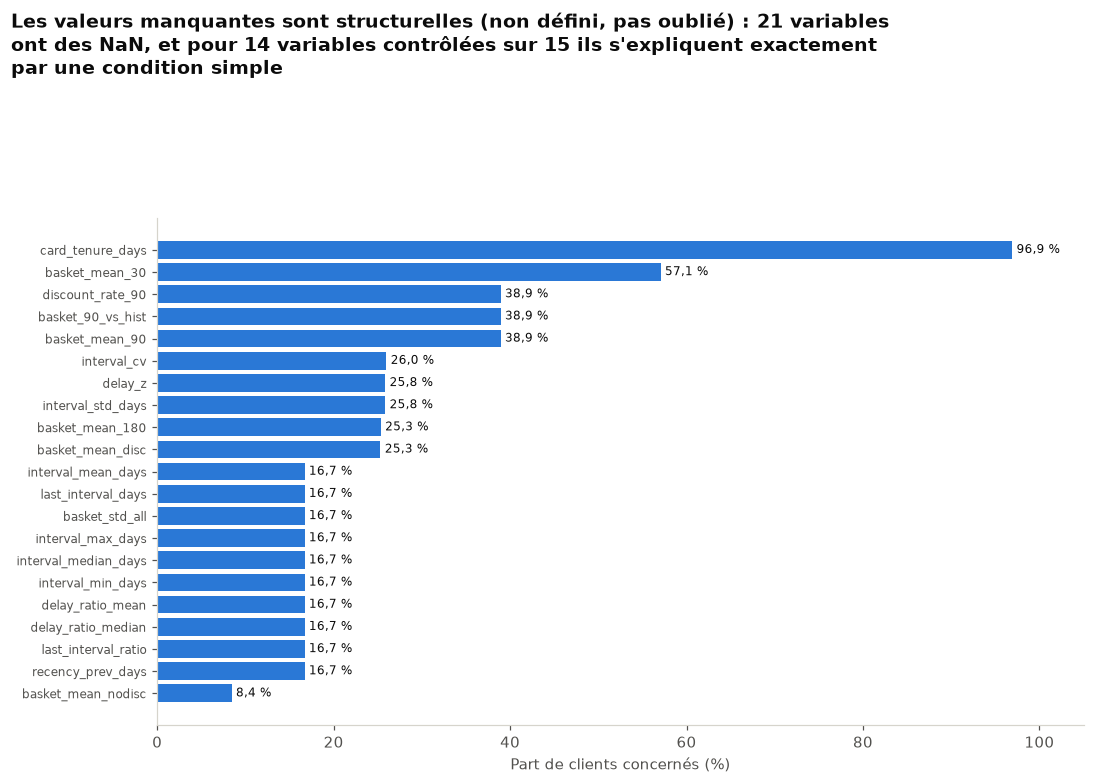

In [17]:
na = X_tr.isna().mean()
na_all = na
na = na[na > .001].sort_values()      # on ignore les 10 clients sans aucun achat (0,006 %)
rules = {  # colonne -> (condition qui rend la valeur non définie, indicateur disponible)
    'recency_days': (X_tr.n_tickets_all == 0, 'n_tickets_all = 0'),
    'interval_mean_days': (X_tr.n_tickets_all <= 1, 'is_one_shot'),
    'interval_median_days': (X_tr.n_tickets_all <= 1, 'is_one_shot'),
    'recency_prev_days': (X_tr.n_tickets_all <= 1, 'is_one_shot'),
    'last_interval_days': (X_tr.n_tickets_all <= 1, 'is_one_shot'),
    'delay_ratio_mean': (X_tr.n_tickets_all <= 1, 'is_one_shot'),
    'interval_std_days': (X_tr.n_tickets_all <= 2, 'has_interval_std'),
    'interval_cv': (X_tr.n_tickets_all <= 2, 'has_interval_std'),
    'delay_z': (X_tr.n_tickets_all <= 2, 'has_interval_std'),
    'basket_mean_30': (X_tr.n_tickets_30 == 0, 'n_tickets_30 = 0'),
    'basket_mean_90': (X_tr.n_tickets_90 == 0, 'n_tickets_90 = 0'),
    'discount_rate_90': (X_tr.n_tickets_90 == 0, 'n_tickets_90 = 0'),
    'basket_mean_180': (X_tr.n_tickets_180 == 0, 'n_tickets_180 = 0'),
    'basket_mean_disc': (X_tr.n_tickets_disc == 0, 'n_tickets_disc = 0'),
    'card_tenure_days': (X_tr.has_card == 0, 'has_card'),
}
chk = []
for col, (cond, ind) in rules.items():
    mism = int((X_tr[col].isna() != cond).sum())
    chk.append({'variable': col, 'part de NaN': X_tr[col].isna().mean(), 'NaN exactement quand': ind, 'écarts': mism})
chk = pd.DataFrame(chk).set_index('variable')
display(chk.style.format({'part de NaN': '{:.1%}'}))

fig, ax = plt.subplots(figsize=(10, 0.28 * len(na) + 1.2))
ax.barh(na.index, na.values * 100, color=c.BLUE)
for i, v in enumerate(na.values * 100):
    ax.text(v + .5, i, fr(v) + ' %', va='center', fontsize=8)
ax.set_xlabel('Part de clients concernés (%)'); ax.set_xlim(0, 105); ax.tick_params(axis='y', labelsize=8)
n_struct = int((chk['écarts'] <= 10).sum())
done(fig, '02_valeurs_manquantes', f"Les valeurs manquantes sont structurelles (non défini, pas oublié) : {len(na)} variables ont des NaN, et pour {n_struct} variables contrôlées sur {len(chk)} ils s'expliquent exactement par une condition simple")

In [18]:
n0 = int((X_tr.n_tickets_all == 0).sum())
md(f'''
**Ce qu'on constate.** Les `NaN` ne sont pas des oublis : ils s'expliquent par une **condition simple et vérifiée** (tableau ci-dessus ; les rares écarts viennent des {n0} clients dont tous les tickets sont des retours, donc sans aucun achat). Quatre règles :

| Cas | Traitement | Pourquoi |
|---|---|---|
| Compte/somme sans achat dans la fenêtre | **0** | Règle métier (slide 86) : pas d'achat = zéro achat |
| Moyenne/ratio non défini (panier moyen sans ticket, intervalle avec 1 seul ticket) | **`NaN` conservé** + indicateur explicite (`is_one_shot`, `has_interval_std`, comptes à 0) | Remplacer par 0 ou par la médiane mélangerait « pas de rythme » et « rythme très court ». Les arbres gèrent le `NaN` ; les modèles linéaires imputeront la médiane **dans leur pipeline, avec l'indicateur** |
| Attribut qualitatif absent (segment de prix, e-mail, civilité, département) | **modalité à part** (`INCONNU` pour le segment de prix et le département, `SANS_EMAIL`, `ND` pour la civilité) + indicateur (`dept_missing`, `anonymous`) | Le manquant est informatif (voir 3.8 et 3.10) ; supprimer les lignes ferait perdre ~{pc(cl_tr.dept.isna().mean(), 0)} des clients pour le seul département |
| Date de carte absente ou invalide | `NaN` (ancienneté) + `has_card` | {int(((cl_tr.card_date.isna()) & cl_tr.has_card).sum())} carte sans date valide et {int((cl_tr.card_date > c.REF_DATE).sum())} cartes postérieures à la date de référence (valeurs corrompues) : traitées comme manquantes |

On n'a **supprimé aucun client** : le test doit être scoré en entier ({nf(len(X_te))} clients) et la suppression de lignes biaiserait l'entraînement.
''')


**Ce qu'on constate.** Les `NaN` ne sont pas des oublis : ils s'expliquent par une **condition simple et vérifiée** (tableau ci-dessus ; les rares écarts viennent des 10 clients dont tous les tickets sont des retours, donc sans aucun achat). Quatre règles :

| Cas | Traitement | Pourquoi |
|---|---|---|
| Compte/somme sans achat dans la fenêtre | **0** | Règle métier (slide 86) : pas d'achat = zéro achat |
| Moyenne/ratio non défini (panier moyen sans ticket, intervalle avec 1 seul ticket) | **`NaN` conservé** + indicateur explicite (`is_one_shot`, `has_interval_std`, comptes à 0) | Remplacer par 0 ou par la médiane mélangerait « pas de rythme » et « rythme très court ». Les arbres gèrent le `NaN` ; les modèles linéaires imputeront la médiane **dans leur pipeline, avec l'indicateur** |
| Attribut qualitatif absent (segment de prix, e-mail, civilité, département) | **modalité à part** (`INCONNU` pour le segment de prix et le département, `SANS_EMAIL`, `ND` pour la civilité) + indicateur (`dept_missing`, `anonymous`) | Le manquant est informatif (voir 3.8 et 3.10) ; supprimer les lignes ferait perdre ~19 % des clients pour le seul département |
| Date de carte absente ou invalide | `NaN` (ancienneté) + `has_card` | 0 carte sans date valide et 4 cartes postérieures à la date de référence (valeurs corrompues) : traitées comme manquantes |

On n'a **supprimé aucun client** : le test doit être scoré en entier (40 106 clients) et la suppression de lignes biaiserait l'entraînement.


### 4.2 Valeurs extrêmes : détection et plafonnement

Le cours propose de les repérer par **écart-type ou percentiles** et de les traiter par **plafonnement ou suppression** (slide 86). On ne supprime **jamais** de clients ; on **plafonne**, à deux niveaux, au **99,9e percentile calculé sur le train** (puis appliqué tel quel au test) :
1. **Au niveau du ticket, avant d'agréger** : panier et nombre d'articles d'un ticket sont ramenés au P99,9 des tickets d'achat. Un ticket à plusieurs milliers d'euros (achat professionnel ou erreur de saisie) ne peut plus, à lui seul, faire d'un client un « gros client ». C'est la recommandation du notebook 01.
2. **Au niveau du client, après agrégation** : comptes, montants et ratios non bornés sont ramenés au P99,9 des clients (borne basse aussi pour les variables qui peuvent être négatives, au P0,1).

*Pourquoi le 99,9e percentile ?* Il ne touche qu'une infime fraction des tickets et des clients (les tableaux ci-dessous la chiffrent), il neutralise les cas manifestement atypiques (un « client » à plusieurs milliers de tickets, probablement un compte professionnel ou collectif) qui tireraient les moyennes et les coefficients des modèles linéaires, mais il **conserve les vrais gros clients**, dont le taux de rachat est élevé : un plafond plus bas écraserait leur signal. Les modèles à arbres y sont insensibles ; la régression logistique et le kNN ne le sont pas.

,"plafond (P99,9 des tickets)",maximum observé,part des tickets plafonnés
panier (€),469,"20,227",0.10%
articles,128,"2,159",0.10%


,asymétrie brute,P99,"P99,5","P99,9 (plafond)",maximum,clients > moy.+5σ,clients plafonnés,asymétrie après plafond
variable,,,,,,,,
tickets_per_active_day,130.5,2.0,2.0,3.0,88.0,189,73,5.7
max_tickets_per_day,81.5,4.0,4.0,7.0,236.0,166,114,2.2
return_amount,62.4,23.6,60.7,271.8,"3,854.7",288,161,17.0
n_returns,51.6,1.0,2.0,6.0,66.0,561,127,12.4
spend_same_month_ly,37.4,762.8,919.3,"1,566.3","33,070.6",213,161,3.3
price_per_item_mean,21.9,20.8,48.8,189.0,468.7,623,160,15.5
n_tickets_180,19.6,74.0,98.0,165.6,"1,860.0",818,161,4.2
n_tickets_90,15.4,39.0,53.0,89.0,855.0,872,156,4.2
n_tickets_all,12.9,155.0,205.0,335.0,"2,985.0",862,160,4.0


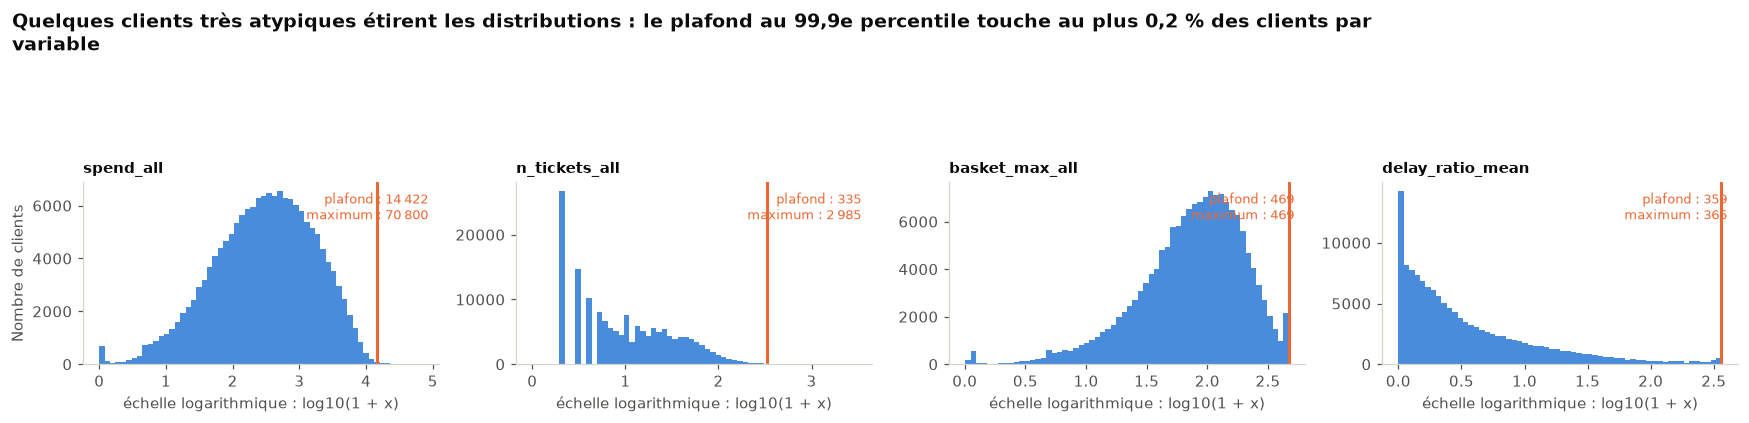

In [19]:
tk_p = tk_tr.loc[~tk_tr['is_return']]
tk_cap = pd.DataFrame({'plafond (P99,9 des tickets)': ticket_caps,
                       'maximum observé': {k: tk_p[k].max() for k in ticket_caps},
                       'part des tickets plafonnés': {k: (tk_p[k] > v).mean() for k, v in ticket_caps.items()}})
tk_cap.index = ['panier (€)' if k == 'basket_value' else 'articles' for k in tk_cap.index]
display(tk_cap.style.format({'plafond (P99,9 des tickets)': '{:,.0f}', 'maximum observé': '{:,.0f}', 'part des tickets plafonnés': '{:.2%}'}))

params = ft.fit_preprocessing(X_tr)                 # APPRIS SUR LE TRAIN UNIQUEMENT
X_tr_p = ft.apply_preprocessing(X_tr, params)
X_te_p = ft.apply_preprocessing(X_te, params)       # même plafonds, mêmes modalités, mêmes colonnes log

rows = []
for col, (lo, hi) in params['caps'].items():
    v = X_tr[col].dropna()
    rows.append({'variable': col, 'asymétrie brute': skew(v), 'P99': v.quantile(.99), 'P99,5': v.quantile(.995), 'P99,9 (plafond)': hi,
                 'maximum': v.max(), 'clients > moy.+5σ': int((v > v.mean() + 5 * v.std()).sum()),
                 'clients plafonnés': int((v > hi).sum() + ((v < lo).sum() if lo is not None else 0)),
                 'asymétrie après plafond': skew(X_tr_p[col].dropna())})
ext = pd.DataFrame(rows).set_index('variable').sort_values('asymétrie brute', ascending=False)
display(ext.head(12).style.format({'asymétrie brute': '{:.1f}', 'P99': '{:,.1f}', 'P99,5': '{:,.1f}', 'P99,9 (plafond)': '{:,.1f}', 'maximum': '{:,.1f}', 'asymétrie après plafond': '{:.1f}'}))

show = ['spend_all', 'n_tickets_all', 'basket_max_all', 'delay_ratio_mean']
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, col in zip(axs, show):
    v = np.log10(1 + X_tr[col].dropna())
    ax.hist(v, bins=60, color=c.BLUE, alpha=.85)
    cap = params['caps'][col][1]
    ax.axvline(np.log10(1 + cap), color=c.ACCENT, lw=2)
    ax.set_title(col, fontsize=10, loc='left')
    ax.text(.97, .95, f"plafond : {fr(cap, 0)}\nmaximum : {fr(X_tr[col].max(), 0)}", transform=ax.transAxes, ha='right', va='top', fontsize=8.5, color=c.ACCENT)
    ax.set_xlabel('échelle logarithmique : log10(1 + x)')
axs[0].set_ylabel('Nombre de clients')
pct_capped = (ext['clients plafonnés'] / len(X_tr)).max()
done(fig, '02_valeurs_extremes', f"Quelques clients très atypiques étirent les distributions : le plafond au 99,9e percentile touche au plus {pc(pct_capped)} des clients par variable")

In [20]:
log_cols = params['log_cols']
sk = pd.DataFrame({'asymétrie après plafond': [skew(X_tr_p[col].dropna()) for col in log_cols],
                   'asymétrie après plafond + log': [skew(X_tr_p[ft.LOG_PREFIX + col].dropna()) for col in log_cols]}, index=log_cols)
md(f'''
**Plafond appliqué à {len(params['caps'])} variables** (comptes, montants, ratios non bornés). Les variables bornées (parts entre 0 et 1, indicateurs, jours) ne sont pas plafonnées.

**Transformation log.** Après plafonnement, {len(log_cols)} variables restent très asymétriques (asymétrie > {ft.SKEW_LOG:.0f}, seuil choisi à l'avance) : pour elles on **ajoute** un jumeau `log_<variable>` = log(1 + x) (la variable d'origine reste). Les modèles à arbres n'en ont pas besoin (ils ne dépendent que de l'ordre des valeurs) ; la régression logistique, les modèles pénalisés et le kNN y gagnent des relations plus linéaires et moins dominées par les grandes valeurs. Les jumeaux log sont des **doublons volontaires** : ils sont exclus de l'audit de corrélation de la section 6.
''')
display(sk.T.style.format('{:.1f}'))


**Plafond appliqué à 56 variables** (comptes, montants, ratios non bornés). Les variables bornées (parts entre 0 et 1, indicateurs, jours) ne sont pas plafonnées.

**Transformation log.** Après plafonnement, 31 variables restent très asymétriques (asymétrie > 3, seuil choisi à l'avance) : pour elles on **ajoute** un jumeau `log_<variable>` = log(1 + x) (la variable d'origine reste). Les modèles à arbres n'en ont pas besoin (ils ne dépendent que de l'ordre des valeurs) ; la régression logistique, les modèles pénalisés et le kNN y gagnent des relations plus linéaires et moins dominées par les grandes valeurs. Les jumeaux log sont des **doublons volontaires** : ils sont exclus de l'audit de corrélation de la section 6.


,n_tickets_7,n_tickets_14,n_tickets_30,n_tickets_60,n_tickets_90,n_tickets_180,n_tickets_all,n_active_days,tickets_per_active_day,spend_30,spend_60,spend_90,spend_180,spend_all,basket_median_all,items_30,items_90,items_all,price_per_item_mean,interval_mean_days,interval_median_days,interval_min_days,delay_ratio_mean,delay_ratio_median,last_interval_ratio,n_tickets_same_month_ly,spend_same_month_ly,n_tickets_disc,n_returns,return_amount,n_regions
asymétrie après plafond,3.8,3.9,4.0,4.2,4.2,4.2,4.0,3.2,5.7,3.5,3.4,3.4,3.3,3.3,3.1,3.5,3.4,3.2,15.5,3.5,3.9,5.3,6.2,5.2,4.3,3.7,3.3,6.4,12.4,17.0,3.3
asymétrie après plafond + log,2.0,1.6,1.2,0.8,0.7,0.4,0.3,0.3,4.6,0.6,0.2,-0.0,-0.4,-0.4,-0.4,0.7,0.2,-0.2,3.2,0.0,0.4,1.3,1.4,1.1,0.9,0.9,0.3,0.7,8.3,7.8,2.8


### 4.3 Regroupement des modalités rares

Un domaine d'e-mail vu chez 3 clients ne peut pas être appris (et créerait une indicatrice presque vide au moment du one-hot, slide 87) : on regroupe les modalités rares dans **`AUTRE`**. La liste des modalités gardées est apprise sur le train, et tout ce qui n'y figure pas (y compris une modalité qui n'apparaîtrait que dans le test) devient `AUTRE`.

In [21]:
rows = []
for col, (mf, always) in ft.RARE_RULES.items():
    rows.append({'variable': col, 'seuil (part des clients)': mf, 'modalités avant': X_tr[col].nunique(), 'modalités gardées': len(params['rare_levels'][col]) + 1,
                 'clients en AUTRE (train)': (X_tr_p[col] == 'AUTRE').mean(), 'clients en AUTRE (test)': (X_te_p[col] == 'AUTRE').mean()})
rare_tab = pd.DataFrame(rows).set_index('variable')
display(rare_tab.style.format({'seuil (part des clients)': '{:.1%}', 'clients en AUTRE (train)': '{:.1%}', 'clients en AUTRE (test)': '{:.1%}'}))
md(f"Les autres variables qualitatives (`civility`, `email_type`, `price_segment`) ont déjà très peu de modalités ({', '.join(f'{col} : {X_tr_p[col].nunique()}' for col in ['civility', 'email_type', 'price_segment'])}) : on les garde telles quelles. **One-hot (N−1 indicatrices, slide 87)** : fait par les pipelines des modèles linéaires (notebook 03) ; les modèles à arbres utiliseront le type catégoriel.")

,seuil (part des clients),modalités avant,modalités gardées,clients en AUTRE (train),clients en AUTRE (test)
variable,,,,,
email_domain,10000.0%,2475,31,3.1%,3.0%
dept,1.0%,100,26,26.9%,27.2%
main_store_region,1.0%,97,31,24.7%,24.8%


Les autres variables qualitatives (`civility`, `email_type`, `price_segment`) ont déjà très peu de modalités (civility : 4, email_type : 4, price_segment : 5) : on les garde telles quelles. **One-hot (N−1 indicatrices, slide 87)** : fait par les pipelines des modèles linéaires (notebook 03) ; les modèles à arbres utiliseront le type catégoriel.

### 4.4 Indicateurs binaires et discrétisation

- **Indicateurs binaires explicites** pour les situations qui changent la nature du client : `is_one_shot`, `has_interval_std`, `is_new_90`, `bought_same_month_ly`, `has_email`, `has_card`, `dept_missing`, `anonymous`, `multicard`, etc. (`int8` 0/1).
- **Discrétisation en classes : uniquement pour l'analyse** (les graphiques de la section 3 : classes de récence, déciles de dépense, quintiles RFM). Les variables envoyées aux modèles restent **continues** : découper en classes ferait perdre de l'information, et les arbres choisissent eux-mêmes leurs seuils.

## 5. Contrôles de qualité de la table finale

Quatre contrôles avant de passer aux modèles : aucune valeur infinie, aucune colonne constante, mêmes colonnes train/test, **distributions comparables entre train et test** (le test est un tirage aléatoire de 20 % de clients : ses distributions doivent ressembler à celles du train).


- Valeurs infinies : **0** ; colonnes constantes : **0** ; mêmes colonnes dans le même ordre pour le train et le test : **oui**.
- Indicateurs très rares (< 2 % de 1) : `card_joined_in_window` (0,9 %), `anonymous` (0,5 %) : conservés car ils isolent des profils particuliers, mais leur signal est étroit.
- **Train vs test** : statistique de Kolmogorov-Smirnov maximale **0.033** (`card_tenure_days`, variable à faible effectif : seuil de rejet à 5 % de 0.044). **1 variable(s) sur 123** dépasse(nt) leur seuil de rejet à 5 % (on en attendrait environ 6 par pur hasard, les variables étant corrélées), mais avec des écarts minimes (la médiane des statistiques est de 0.003). Distance en variation totale maximale pour les variables qualitatives : **0.009** (`main_store_region`).
- Seul écart structurel connu : `main_store_client_share` est mesurée dans chaque échantillon (part des clients de la base présents dans le magasin) ; plus bruitée sur le test (20 % des clients), sa statistique est de 0.023 contre 0.005 entre deux moitiés du train.


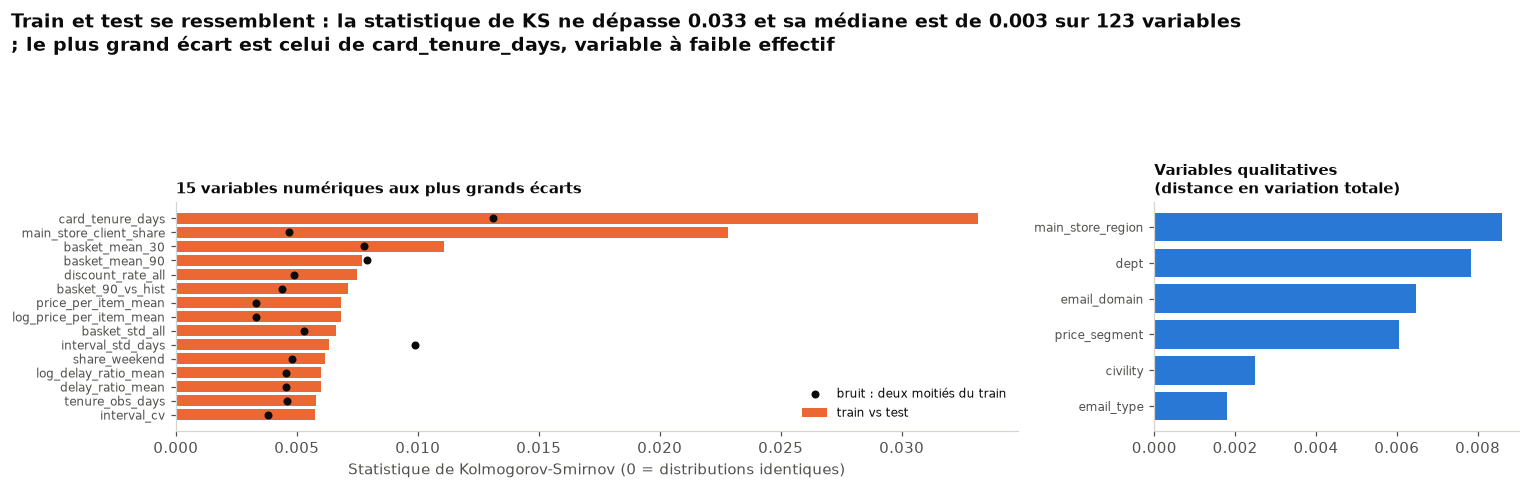

In [22]:
num_bin = [col for col in X_tr_p.columns if ft.SPEC.loc[col.removeprefix(ft.LOG_PREFIX), 'type'] != 'cat']
cat_cols = ft.CAT_COLS

# 1) pas d'infini, 2) pas de colonne constante, 3) mêmes colonnes
vals = X_tr_p[num_bin].to_numpy(dtype=float)
n_inf = int(np.isinf(vals).sum())
const = [col for col in X_tr_p.columns if X_tr_p[col].nunique(dropna=False) <= 1]
assert n_inf == 0 and not const and list(X_tr_p.columns) == list(X_te_p.columns)
rare_bin = [(col, X_tr_p[col].mean()) for col in X_tr_p.columns if ft.SPEC.loc[col.removeprefix(ft.LOG_PREFIX), 'type'] == 'bin' and X_tr_p[col].mean() < .02]

# 4) KS train vs test, comparé au bruit d'échantillonnage (deux sous-échantillons du train de mêmes tailles)
rng = np.random.default_rng(c.SEED)
perm = rng.permutation(len(X_tr_p)); a, b = perm[:len(X_te_p)], perm[len(X_te_p):]
ks = {}
for col in num_bin:
    v1, v2 = X_tr_p[col].dropna(), X_te_p[col].dropna()
    crit = 1.36 * np.sqrt((len(v1) + len(v2)) / (len(v1) * len(v2)))          # seuil de rejet du test de KS à 5 %
    ks[col] = (ks_2samp(v1, v2).statistic, ks_2samp(X_tr_p[col].iloc[b].dropna(), X_tr_p[col].iloc[a].dropna()).statistic, crit)
ks = pd.DataFrame(ks, index=['train vs test', 'train vs train (bruit)', 'seuil 5 %']).T.sort_values('train vs test', ascending=False)
n_exceed = int((ks['train vs test'] > ks['seuil 5 %']).sum())
tvd = {col: 0.5 * (X_tr_p[col].value_counts(normalize=True).sub(X_te_p[col].value_counts(normalize=True), fill_value=0).abs().sum()) for col in cat_cols}
tvd = pd.Series(tvd).sort_values(ascending=False)

md(f'''
- Valeurs infinies : **{n_inf}** ; colonnes constantes : **{len(const)}** ; mêmes colonnes dans le même ordre pour le train et le test : **oui**.
- Indicateurs très rares (< 2 % de 1) : {', '.join(f'`{k}` ({pc(v)})' for k, v in rare_bin)} : conservés car ils isolent des profils particuliers, mais leur signal est étroit.
- **Train vs test** : statistique de Kolmogorov-Smirnov maximale **{ks['train vs test'].iloc[0]:.3f}** (`{ks.index[0]}`, variable à faible effectif : seuil de rejet à 5 % de {ks['seuil 5 %'].iloc[0]:.3f}). **{n_exceed} variable(s) sur {len(ks)}** dépasse(nt) leur seuil de rejet à 5 % (on en attendrait environ {0.05 * len(ks):.0f} par pur hasard, les variables étant corrélées), mais avec des écarts minimes (la médiane des statistiques est de {ks['train vs test'].median():.3f}). Distance en variation totale maximale pour les variables qualitatives : **{tvd.iloc[0]:.3f}** (`{tvd.index[0]}`).
- Seul écart structurel connu : `main_store_client_share` est mesurée dans chaque échantillon (part des clients de la base présents dans le magasin) ; plus bruitée sur le test (20 % des clients), sa statistique est de {ks.loc['main_store_client_share', 'train vs test']:.3f} contre {ks.loc['main_store_client_share', 'train vs train (bruit)']:.3f} entre deux moitiés du train.
''')

fig, axs = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={'width_ratios': [3, 1.3]})
top = ks.head(15)[::-1]
axs[0].barh(top.index, top['train vs test'], color=c.ACCENT, label='train vs test')
axs[0].scatter(top['train vs train (bruit)'], range(len(top)), color=c.INK, zorder=3, s=18, label='bruit : deux moitiés du train')
axs[0].set_xlabel('Statistique de Kolmogorov-Smirnov (0 = distributions identiques)'); axs[0].legend(fontsize=8, frameon=False, loc='lower right')
axs[0].tick_params(axis='y', labelsize=8); axs[0].set_title('15 variables numériques aux plus grands écarts', fontsize=10, loc='left')
axs[1].barh(tvd.index[::-1], tvd.values[::-1], color=c.BLUE); axs[1].set_title('Variables qualitatives\n(distance en variation totale)', fontsize=10, loc='left')
axs[1].tick_params(axis='y', labelsize=8)
done(fig, '02_train_vs_test', f"Train et test se ressemblent : la statistique de KS ne dépasse {ks['train vs test'].iloc[0]:.3f} et sa médiane est de {ks['train vs test'].median():.3f} sur {len(ks)} variables ; le plus grand écart est celui de {ks.index[0]}, variable à faible effectif")

## 6. Corrélations et quasi-doublons

Beaucoup de variables mesurent des choses voisines (tickets sur 90 et 180 jours, dépense et nombre d'articles). Corrélation de **Spearman** (rang) : robuste aux valeurs extrêmes et aux relations non linéaires. On regarde (1) la matrice détaillée, (2) la corrélation moyenne **entre familles**, (3) les paires à |ρ| > 0,95, **dont on retire la seconde** : à information quasi identique, on garde la variable de la fenêtre la plus simple.

*Règle de retrait, fixée avant de regarder la cible* : dans l'ordre du dictionnaire (récence, fréquence, montant, rythme…), on garde la première variable d'une paire quasi doublon et on retire la suivante. Le retrait n'utilise **pas** l'AUC. Une variable retirée n'est pas supprimée du dictionnaire : elle y figure avec `kept = False` et la raison.

*Lien avec le cours* : analyse des distributions et contrôle des corrélations (slides 51, 87).

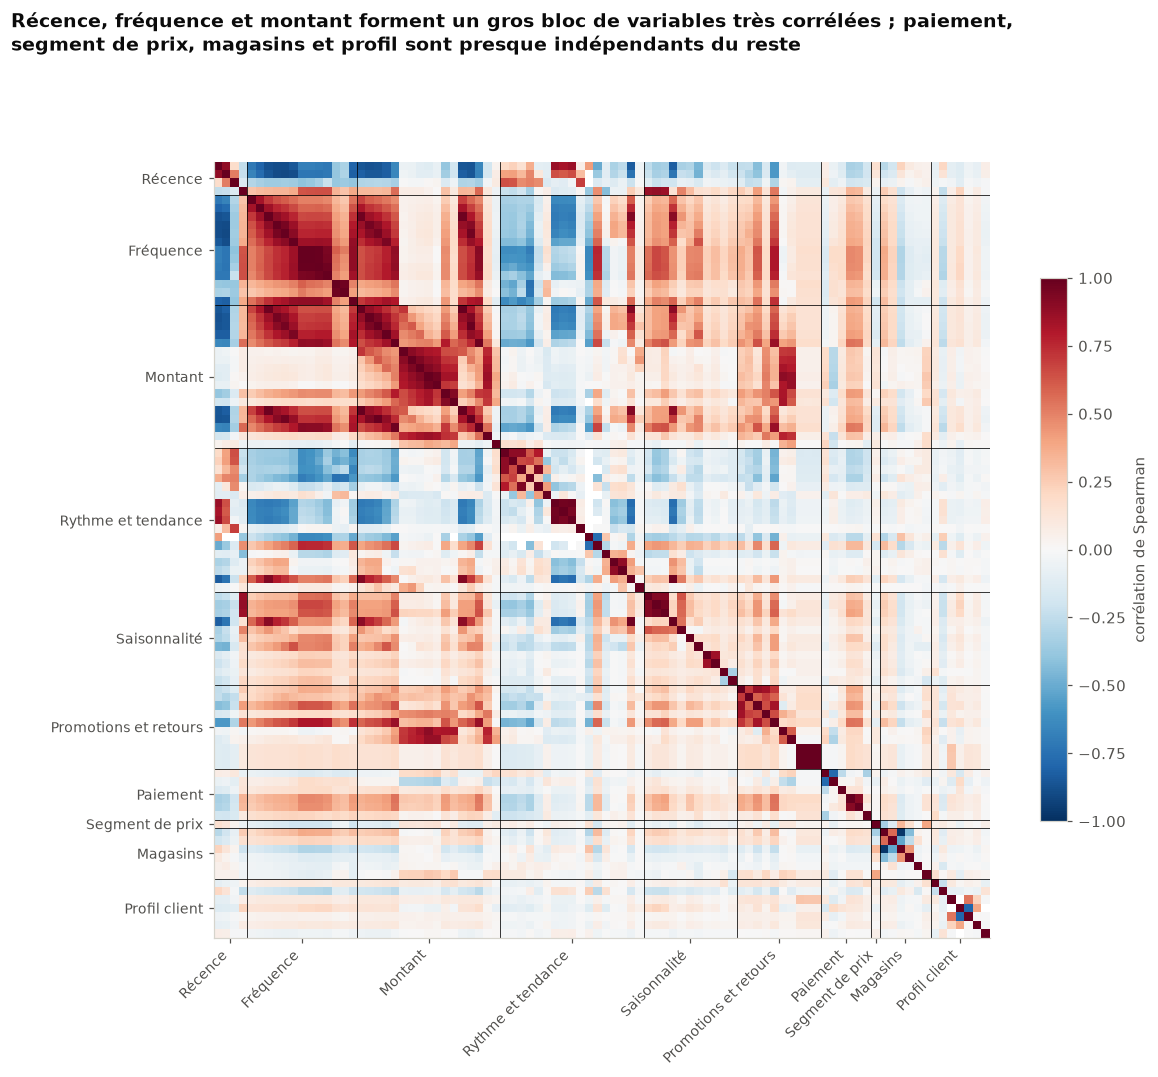

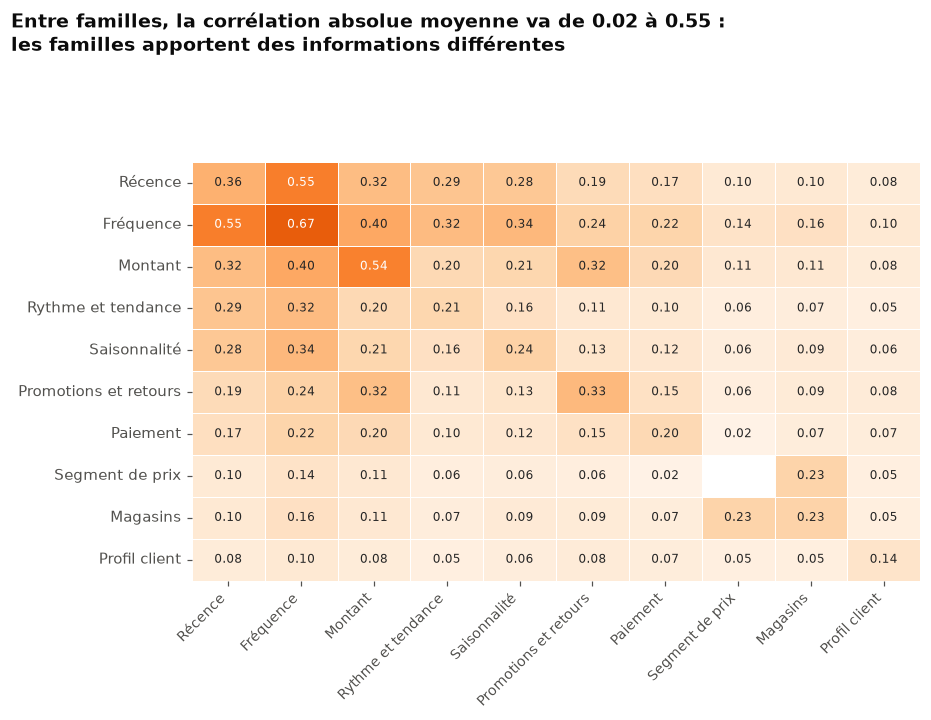

In [23]:
base_cols = [col for col in X_tr_p.columns if not col.startswith(ft.LOG_PREFIX) and ft.SPEC.loc[col, 'type'] != 'cat']
corr = X_tr_p[base_cols].rank().corr()                # Spearman (rangs ; NaN exclus par paire)
fam = ft.SPEC.loc[base_cols, 'group']

# --- (1) matrice détaillée, ordonnée par famille
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
bounds = np.r_[0, np.cumsum(fam.groupby(fam, sort=False).size().values)]
for b_ in bounds[1:-1]:
    ax.axhline(b_ - .5, color='k', lw=.5); ax.axvline(b_ - .5, color='k', lw=.5)
centers = (bounds[:-1] + bounds[1:]) / 2 - .5
ax.set_xticks(centers); ax.set_xticklabels(GROUPS, rotation=45, ha='right', fontsize=9)
ax.set_yticks(centers); ax.set_yticklabels(GROUPS, fontsize=9)
plt.colorbar(im, ax=ax, shrink=.7, label='corrélation de Spearman')
done(fig, '02_correlations_detail', 'Récence, fréquence et montant forment un gros bloc de variables très corrélées ; paiement, segment de prix, magasins et profil sont presque indépendants du reste')

# --- (2) corrélation absolue moyenne entre familles
fm = pd.DataFrame(index=GROUPS, columns=GROUPS, dtype=float)
for g1 in GROUPS:
    for g2 in GROUPS:
        c1, c2 = list(fam.index[fam == g1]), list(fam.index[fam == g2])
        sub = corr.loc[c1, c2].abs()
        fm.loc[g1, g2] = (np.nansum(sub.values) - (len(c1) if g1 == g2 else 0)) / (sub.size - (len(c1) if g1 == g2 else 0))
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(fm, annot=True, fmt='.2f', cmap='Oranges', vmin=0, vmax=1, cbar=False, ax=ax, linewidths=.5, annot_kws={'fontsize': 8})
ax.set_xticklabels(GROUPS, rotation=45, ha='right', fontsize=9)
fm_off = fm.values[~np.eye(len(GROUPS), dtype=bool)]
done(fig, '02_correlations_familles', f"Entre familles, la corrélation absolue moyenne va de {fm_off.min():.2f} à {fm_off.max():.2f} : les familles apportent des informations différentes")

In [24]:
# --- (3) quasi-doublons |rho| > 0,95 : on garde la première variable (ordre du dictionnaire), on retire la suivante
THR = .95
keep_order, dropped = [], {}
for col in base_cols:
    dup = next((k for k in keep_order if abs(corr.loc[k, col]) > THR), None)
    if dup is None:
        keep_order.append(col)
    else:
        dropped[col] = (dup, corr.loc[dup, col])
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().loc[lambda s: s.abs() > THR].sort_values(ascending=False))
dup_tab = pd.DataFrame([{'variable retirée': k, 'gardée à la place': v[0], 'corrélation (Spearman)': v[1]} for k, v in dropped.items()]).set_index('variable retirée')
display(dup_tab.style.format({'corrélation (Spearman)': '{:.3f}'}) if len(dup_tab) else 'Aucun quasi-doublon')
md(f"**{len(pairs)} paires** ont |ρ| > {THR} ; on retire **{len(dropped)} variable(s)**, il en reste **{len(keep_order)}** parmi les variables de base (hors jumeaux log). Redondances *logiques* conservées volontairement (non mesurées ici car qualitatives) : `has_email` ⇔ `email_type ≠ SANS_EMAIL`, `dept_missing` ⇔ `dept = INCONNU`, `anonymous` ≈ `civility = ND`, `price_segment_missing` ⇔ `price_segment = INCONNU`. Les modèles choisiront ce qu'ils veulent ; les modèles pénalisés (Lasso, ElasticNet) neutraliseront les doublons.")

,gardée à la place,corrélation (Spearman)
variable retirée,,
n_tickets_90,n_tickets_60,0.950
n_active_days,n_tickets_all,0.997
n_active_weeks,n_tickets_all,0.987
tickets_per_active_day,max_tickets_per_day,0.974
spend_30,n_tickets_30,0.971
spend_60,n_tickets_60,0.960
basket_median_all,basket_mean_all,0.962
items_30,n_tickets_30,0.975
items_90,spend_90,0.991


**23 paires** ont |ρ| > 0.95 ; on retire **17 variable(s)**, il en reste **75** parmi les variables de base (hors jumeaux log). Redondances *logiques* conservées volontairement (non mesurées ici car qualitatives) : `has_email` ⇔ `email_type ≠ SANS_EMAIL`, `dept_missing` ⇔ `dept = INCONNU`, `anonymous` ≈ `civility = ND`, `price_segment_missing` ⇔ `price_segment = INCONNU`. Les modèles choisiront ce qu'ils veulent ; les modèles pénalisés (Lasso, ElasticNet) neutraliseront les doublons.

## 7. Quelle variable porte le plus de signal ? AUC univariée et déciles de rachat

L'**AUC univariée** est l'AUC obtenue en utilisant une seule variable comme score (0,5 = aucun signal ; on retient la valeur la plus éloignée de 0,5, donc dans [0,5 ; 1]). C'est une **exploration descriptive**, pas un critère de sélection : elle ne sert **pas** à modifier ni à retirer des variables (le tri se fait par les modèles, slide 88). Les `NaN` sont remplacés par la médiane pour ce calcul (la couverture est indiquée). Pour les variables qualitatives, le score est le taux de rachat de la modalité mesuré **hors du pli** (validation croisée sur les plis communs) : sinon il serait optimiste.

,group,type,auc,auc_signed,direction,coverage,kept_after_dedup
name,,,,,,,
n_tickets_90,Fréquence,num,0.852,0.852,croissant,100%,False
n_tickets_60,Fréquence,num,0.850,0.850,croissant,100%,True
n_tickets_180,Fréquence,num,0.846,0.846,croissant,100%,True
n_tickets_30,Fréquence,num,0.837,0.837,croissant,100%,True
active_weeks_share,Fréquence,num,0.833,0.833,croissant,100%,True
items_90,Montant,num,0.832,0.832,croissant,100%,False
recency_prev_days,Récence,num,0.168,0.832,décroissant,83%,True
n_active_days,Fréquence,num,0.829,0.829,croissant,100%,False
n_tickets_all,Fréquence,num,0.829,0.829,croissant,100%,True


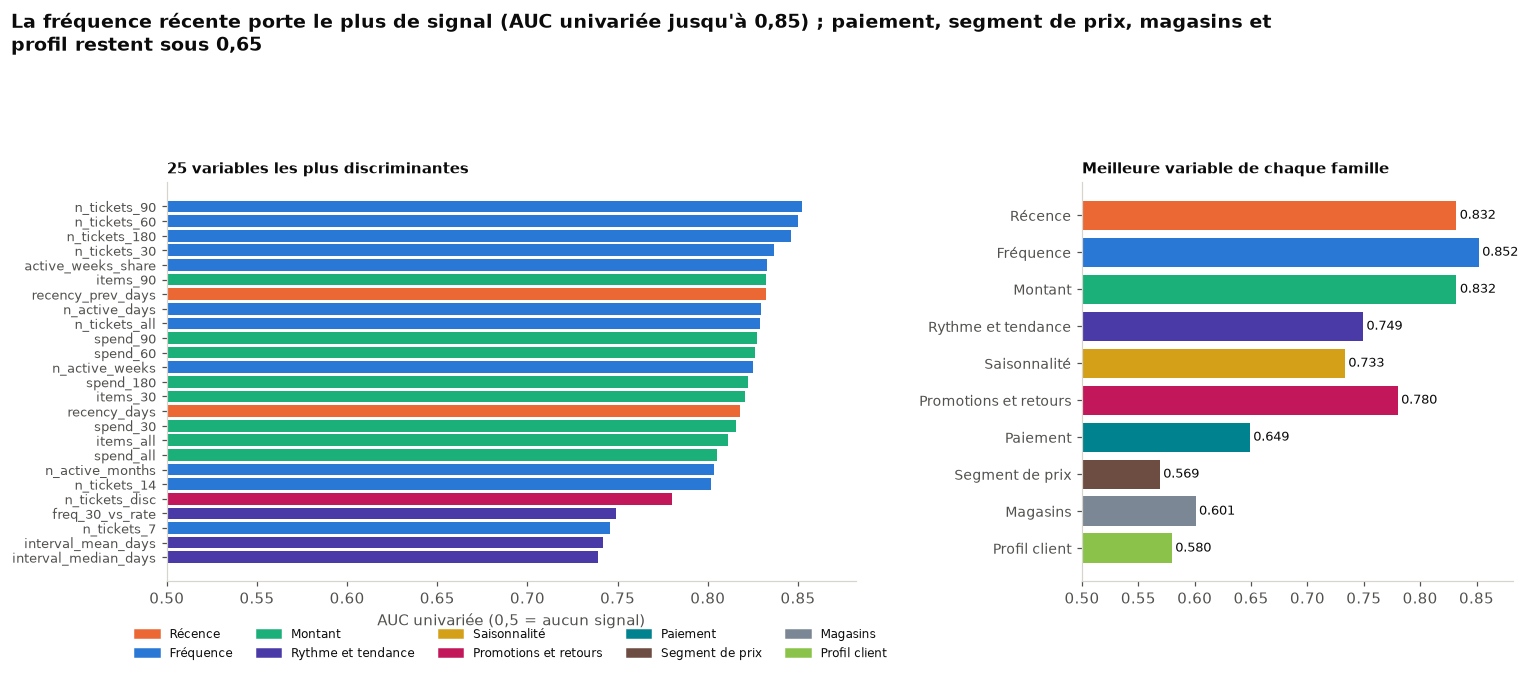

In [25]:
folds = c.get_folds()
yv = y.to_numpy()


def auc_num(col):
    v = X_tr_p[col]
    cov = v.notna().mean()
    a = roc_auc_score(yv, v.fillna(v.median()))
    return a, cov


def auc_cat(col):
    s = X_tr_p[col]
    oof = pd.Series(np.nan, index=s.index)
    for k in range(c.N_FOLDS):
        tr = (folds != k).to_numpy()
        rate = y[tr].groupby(s[tr]).mean()
        oof[~tr] = s[~tr].map(rate).fillna(y[tr].mean())
    return roc_auc_score(yv, oof), 1.0


rows = []
for col in base_cols + cat_cols:
    typ = ft.SPEC.loc[col, 'type']
    a, cov = auc_cat(col) if typ == 'cat' else auc_num(col)
    rows.append({'name': col, 'group': ft.SPEC.loc[col, 'group'], 'type': typ, 'auc': a, 'auc_signed': max(a, 1 - a),
                 'direction': ('croissant' if a >= .5 else 'décroissant') if typ != 'cat' else 'taux par modalité', 'coverage': cov})
auc_df = pd.DataFrame(rows).set_index('name').sort_values('auc_signed', ascending=False)
auc_df['kept_after_dedup'] = ~auc_df.index.isin(list(dropped))
c.save_result('02_univariate_auc', auc_df)
display(auc_df.head(15).style.format({'auc': '{:.3f}', 'auc_signed': '{:.3f}', 'coverage': '{:.0%}'}))

fig, axs = plt.subplots(1, 2, figsize=(14, 6.2), gridspec_kw={'width_ratios': [1.6, 1]})
top = auc_df.head(25)[::-1]
axs[0].barh(top.index, top['auc_signed'], color=[GCOL[g] for g in top['group']])
axs[0].axvline(.5, color=c.INK2, lw=1); axs[0].set_xlim(.5, auc_df['auc_signed'].max() + .03)
axs[0].tick_params(axis='y', labelsize=8.5); axs[0].set_xlabel('AUC univariée (0,5 = aucun signal)')
axs[0].set_title('25 variables les plus discriminantes', fontsize=10, loc='left')
axs[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=GCOL[g]) for g in GROUPS], labels=GROUPS, fontsize=8, frameon=False, loc='upper center', bbox_to_anchor=(.5, -.09), ncol=5)
bf = auc_df.groupby('group')['auc_signed'].max().loc[GROUPS][::-1]
axs[1].barh(bf.index, bf.values, color=[GCOL[g] for g in bf.index]); axs[1].set_xlim(.5, bf.max() + .03)
for i, v in enumerate(bf.values):
    axs[1].text(v + .003, i, f'{v:.3f}', va='center', fontsize=8.5)
axs[1].set_title('Meilleure variable de chaque famille', fontsize=10, loc='left'); axs[1].tick_params(axis='y', labelsize=9)
prof_best = auc_df.groupby('group')['auc_signed'].max().loc[['Paiement', 'Segment de prix', 'Magasins', 'Profil client']].max()
done(fig, '02_auc_univariee', f"La fréquence récente porte le plus de signal (AUC univariée jusqu'à {fr(auc_df['auc_signed'].max(), 2)}) ; paiement, segment de prix, magasins et profil restent sous {fr(prof_best, 2)}")

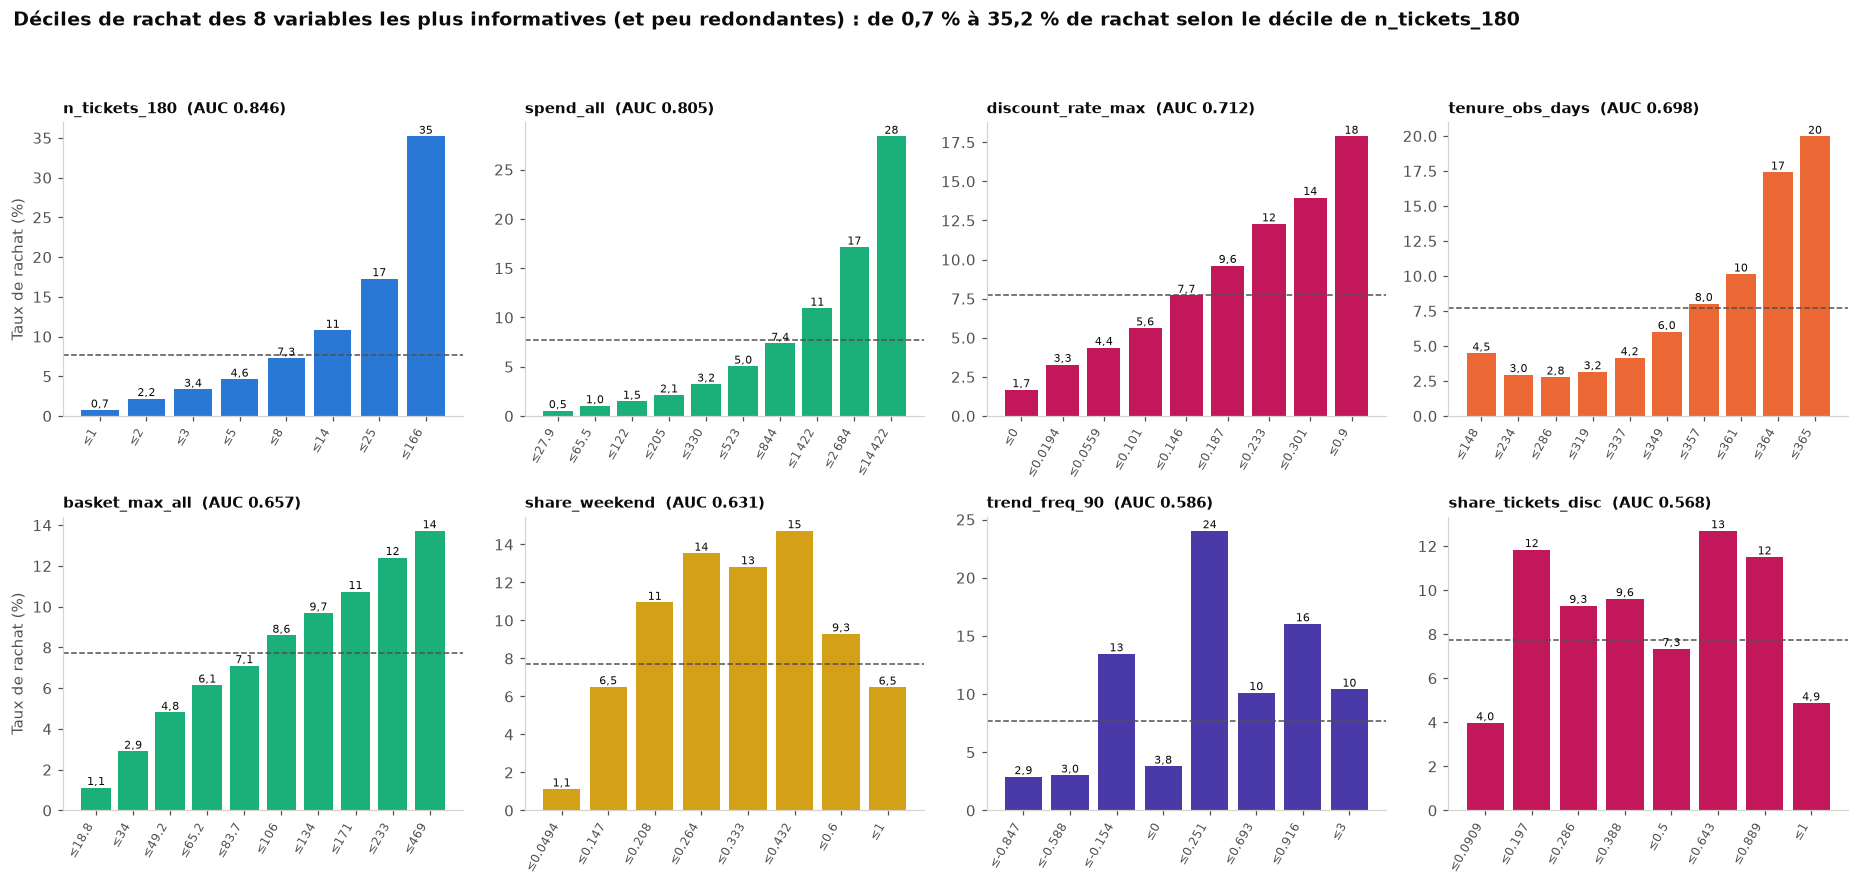

Variables choisies (meilleures AUC univariées, peu redondantes entre elles, |ρ| < 0,8) : `n_tickets_180`, `spend_all`, `discount_rate_max`, `tenure_obs_days`, `basket_max_all`, `share_weekend`, `trend_freq_90`, `share_tickets_disc`.

In [26]:
# 6 à 8 variables informatives et peu redondantes entre elles (|rho| < 0,8), parmi les variables numériques gardées
cand = [col for col in auc_df.index if col in keep_order and ft.SPEC.loc[col, 'type'] == 'num' and auc_df.loc[col, 'coverage'] > .9
        and rate_by(D[col].fillna(D[col].median()), q=10).shape[0] >= 8]      # au moins 8 classes de quantiles distinctes
picked = []
for col in cand:
    if all(abs(corr.loc[col, p]) < .8 for p in picked):
        picked.append(col)
    if len(picked) == 8:
        break

fig, axs = plt.subplots(2, 4, figsize=(17, 8))
for ax, col in zip(axs.ravel(), picked):
    t = rate_by(D[col].fillna(D[col].median()).clip(upper=X_tr_p[col].max(), lower=X_tr_p[col].min()), q=10)
    r = t['rate'].to_numpy() * 100
    ax.bar(range(len(t)), r, color=GCOL[ft.SPEC.loc[col, 'group']])
    ax.axhline(base * 100, color=c.INK2, ls='--', lw=1)
    ax.set_xticks(range(len(t))); ax.set_xticklabels(t.index, rotation=60, ha='right', fontsize=8)
    ax.set_title(f"{col}  (AUC {auc_df.loc[col, 'auc_signed']:.3f})", fontsize=10, loc='left')
    for i_, v_ in enumerate(r):
        ax.text(i_, v_, fr(v_, 0) if v_ >= 10 else fr(v_), ha='center', va='bottom', fontsize=7)
for ax in axs[:, 0]:
    ax.set_ylabel('Taux de rachat (%)')
dec_gap = {col: rate_by(D[col].fillna(D[col].median()), q=10)['rate'] for col in picked}
top_col = picked[0]
done(fig, '02_deciles_rachat',
     f"Déciles de rachat des {len(picked)} variables les plus informatives (et peu redondantes) : de {fr(100 * dec_gap[top_col].min())} % à {fr(100 * dec_gap[top_col].max())} % de rachat selon le décile de {top_col}")
md(f"Variables choisies (meilleures AUC univariées, peu redondantes entre elles, |ρ| < 0,8) : {', '.join(f'`{p}`' for p in picked)}.")

## 8. Test de non-régression : les variables apportent-elles plus que la récence seule ?

Le brief le dit : **le modèle doit faire mieux que la récence seule**. Trois repères sur le train, avec les plis communs `c.get_folds()` :
1. **Règle de récence** (score = −jours depuis le dernier achat) : pas d'apprentissage, donc son AUC sur le train est directement honnête.
2. **LightGBM de contrôle** (200 arbres, valeurs par défaut raisonnables, `n_jobs=2`, **aucun réglage**) en ajoutant les familles de variables **une à une dans l'ordre du notebook**. C'est une ablation *descriptive* (l'ordre est fixé à l'avance, ce n'est pas une recherche de sélection) ; le but est de voir ce que chaque famille ajoute.
3. Le modèle complet est un **contrôle**, pas un modèle candidat : les modèles de référence sont dans les notebooks 03 et 04.

In [27]:
import lightgbm as lgb
final_cols = [col for col in X_tr_p.columns if col.removeprefix(ft.LOG_PREFIX) not in dropped]
X_fin_tr, X_fin_te = X_tr_p[final_cols], X_te_p[final_cols]

# 1) règle de récence
score_rec = (-X_tr.recency_days).fillna(-1e3)
rep_rec = c.cv_report(y, score_rec, folds)
rec_auc_all = roc_auc_score(yv, score_rec)

# 2) LightGBM de contrôle
cat_levels = {col: sorted(X_fin_tr[col].unique()) for col in cat_cols}
LGB = dict(n_estimators=200, learning_rate=.05, num_leaves=31, min_child_samples=100, subsample=.8, subsample_freq=1,
           colsample_bytree=.8, reg_lambda=1.0, n_jobs=2, random_state=c.SEED, verbose=-1)


def as_lgb(X, cols):
    Z = X[cols].copy()
    for col in cols:
        if col in cat_levels:
            Z[col] = pd.Categorical(Z[col], categories=cat_levels[col])
    return Z


def cv_lgb(cols):
    Z = as_lgb(X_fin_tr, cols)
    oof = pd.Series(0.0, index=Z.index)
    for k in range(c.N_FOLDS):
        tr = np.where(folds.to_numpy() != k)[0]; va = np.where(folds.to_numpy() == k)[0]
        m = lgb.LGBMClassifier(**LGB).fit(Z.iloc[tr], yv[tr])
        oof.iloc[va] = m.predict_proba(Z.iloc[va])[:, 1]
    return oof


t0 = time.time()
ladder, cols_so_far, steps = [], [], []
for g in GROUPS:
    cols_so_far += [col for col in final_cols if not col.startswith(ft.LOG_PREFIX) and ft.SPEC.loc[col, 'group'] == g]
    oof_full = cv_lgb(cols_so_far)
    rep = c.cv_report(y, oof_full, folds)
    ladder.append({'étape': ('' if g == GROUPS[0] else '+ ') + g, 'variables': len(cols_so_far), **rep})
ladder = pd.DataFrame(ladder).set_index('étape')
t_lgb = time.time() - t0
rep_full = c.cv_report(y, oof_full, folds)
display(ladder[['variables', 'auc', 'auc_fold_mean', 'auc_fold_std', 'precision_top10', 'recall_top10', 'lift_top10']]
        .style.format({'auc': '{:.4f}', 'auc_fold_mean': '{:.4f}', 'auc_fold_std': '{:.4f}', 'precision_top10': '{:.1%}', 'recall_top10': '{:.1%}', 'lift_top10': '{:.2f}'}))
md(f'''
| Repère (train, hors-échantillon) | AUC | Précision top 10 % | Rappel top 10 % | Lift top 10 % |
|---|---|---|---|---|
| Règle de récence seule | **{rep_rec['auc']:.4f}** (écart-type entre plis {rep_rec['auc_fold_std']:.4f}) | {pc(rep_rec['precision_top10'])} | {pc(rep_rec['recall_top10'])} | {rep_rec['lift_top10']:.2f} |
| LightGBM de contrôle, toutes les variables | **{rep_full['auc']:.4f}** (écart-type {rep_full['auc_fold_std']:.4f}) | {pc(rep_full['precision_top10'])} | {pc(rep_full['recall_top10'])} | {rep_full['lift_top10']:.2f} |
''')

,variables,auc,auc_fold_mean,auc_fold_std,precision_top10,recall_top10,lift_top10
étape,,,,,,,
Récence,4,0.8587,0.8588,0.0035,35.5%,46.0%,4.60
+ Fréquence,13,0.8708,0.8709,0.0031,39.3%,50.9%,5.09
+ Montant,24,0.8706,0.8707,0.0033,39.2%,50.7%,5.07
+ Rythme et tendance,39,0.8709,0.8709,0.0032,39.3%,50.9%,5.09
+ Saisonnalité,48,0.8779,0.8780,0.0024,40.6%,52.6%,5.26
+ Promotions et retours,56,0.8777,0.8778,0.0023,40.8%,52.8%,5.28
+ Paiement,62,0.8778,0.8778,0.0022,40.7%,52.6%,5.26
+ Segment de prix,64,0.8778,0.8779,0.0024,40.6%,52.6%,5.26
+ Magasins,70,0.8779,0.8779,0.0025,40.4%,52.3%,5.23



| Repère (train, hors-échantillon) | AUC | Précision top 10 % | Rappel top 10 % | Lift top 10 % |
|---|---|---|---|---|
| Règle de récence seule | **0.8180** (écart-type entre plis 0.0035) | 23,5 % | 30,4 % | 3.04 |
| LightGBM de contrôle, toutes les variables | **0.8775** (écart-type 0.0018) | 40,4 % | 52,3 % | 5.23 |


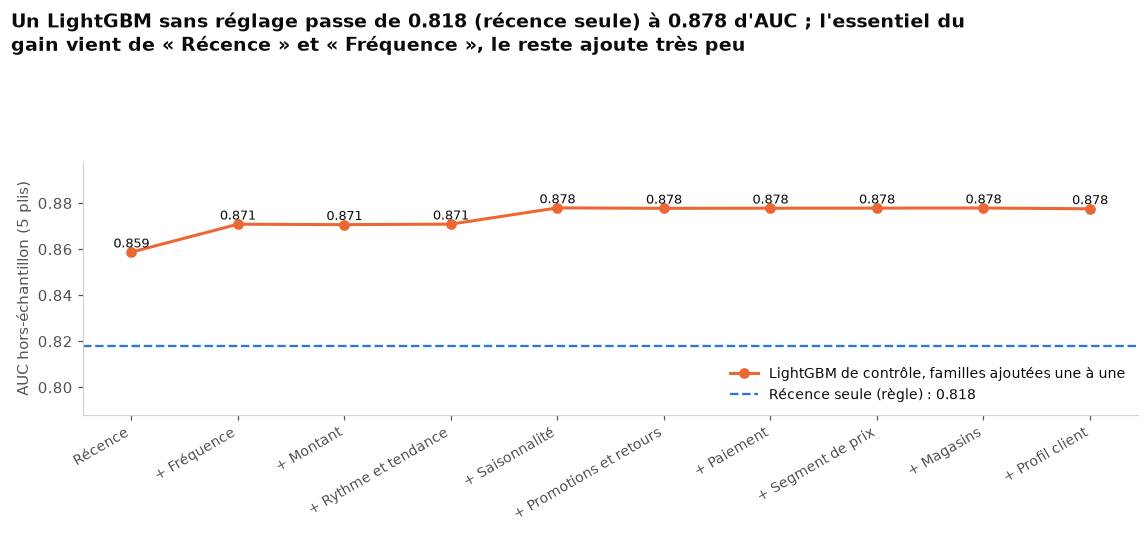

**Lecture.** Un LightGBM sans réglage atteint une AUC de **0.878** contre **0.818** pour la règle de récence seule (+0.059). Dans le top 10 % des clients, la précision passe de 23,5 % à 40,4 % (lift de 3.04 à 5.23). Gain apporté par chaque famille (en points d'AUC, la première étant comparée à la règle de récence) : Récence +0.041, Fréquence +0.012, Montant -0.000, Rythme et tendance +0.000, Saisonnalité +0.007, Promotions et retours -0.000, Paiement +0.000, Segment de prix +0.000, Magasins +0.000, Profil client -0.000. Deux enseignements : (1) même la famille « récence » seule, donnée à un arbre, fait mieux que la règle (l'arbre combine dernier achat, avant-dernier achat, dernier intervalle et ancienneté) ; (2) les familles suivantes n'ajoutent pas toutes autant : certaines sont redondantes avec la fréquence (les corrélations de la section 6). *Le test de non-régression est passé* : la table apporte bien plus que la récence seule. (Calcul : 1.0 min ; cette AUC est une **indication** : pas de réglage, pas de soumission.)

In [28]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
xs = np.arange(len(ladder))
ax.plot(xs, ladder['auc'], marker='o', color=c.ACCENT, lw=2, label='LightGBM de contrôle, familles ajoutées une à une')
ax.axhline(rep_rec['auc'], color=c.BLUE, ls='--', lw=1.5, label=f"Récence seule (règle) : {rep_rec['auc']:.3f}")
for i, v in enumerate(ladder['auc']):
    ax.text(i, v + .002, f'{v:.3f}', ha='center', fontsize=8.5)
ax.set_xticks(xs); ax.set_xticklabels(ladder.index, rotation=30, ha='right', fontsize=9)
ax.set_ylabel('AUC hors-échantillon (5 plis)'); ax.set_ylim(rep_rec['auc'] - .03, ladder['auc'].max() + .02); ax.legend(frameon=False, fontsize=9, loc='lower right')
gain = rep_full['auc'] - rep_rec['auc']
steps = ladder['auc'].diff().fillna(ladder['auc'].iloc[0] - rep_rec['auc'])      # gain de chaque famille ajoutée (la 1re par rapport à la règle de récence)
top2 = steps.sort_values(ascending=False).index[:2]
done(fig, '02_apport_familles', f"Un LightGBM sans réglage passe de {rep_rec['auc']:.3f} (récence seule) à {rep_full['auc']:.3f} d'AUC ; l'essentiel du gain vient de « {top2[0].strip('+ ')} » et « {top2[1].strip('+ ')} », le reste ajoute très peu")
md(f'''**Lecture.** Un LightGBM sans réglage atteint une AUC de **{rep_full['auc']:.3f}** contre **{rep_rec['auc']:.3f}** pour la règle de récence seule (+{gain:.3f}). Dans le top 10 % des clients, la précision passe de {pc(rep_rec['precision_top10'])} à {pc(rep_full['precision_top10'])} (lift de {rep_rec['lift_top10']:.2f} à {rep_full['lift_top10']:.2f}). Gain apporté par chaque famille (en points d'AUC, la première étant comparée à la règle de récence) : {', '.join(f"{k.strip('+ ')} {v:+.3f}" for k, v in steps.items())}. Deux enseignements : (1) même la famille « récence » seule, donnée à un arbre, fait mieux que la règle (l'arbre combine dernier achat, avant-dernier achat, dernier intervalle et ancienneté) ; (2) les familles suivantes n'ajoutent pas toutes autant : certaines sont redondantes avec la fréquence (les corrélations de la section 6). *Le test de non-régression est passé* : la table apporte bien plus que la récence seule. (Calcul : {t_lgb / 60:.1f} min ; cette AUC est une **indication** : pas de réglage, pas de soumission.)''')

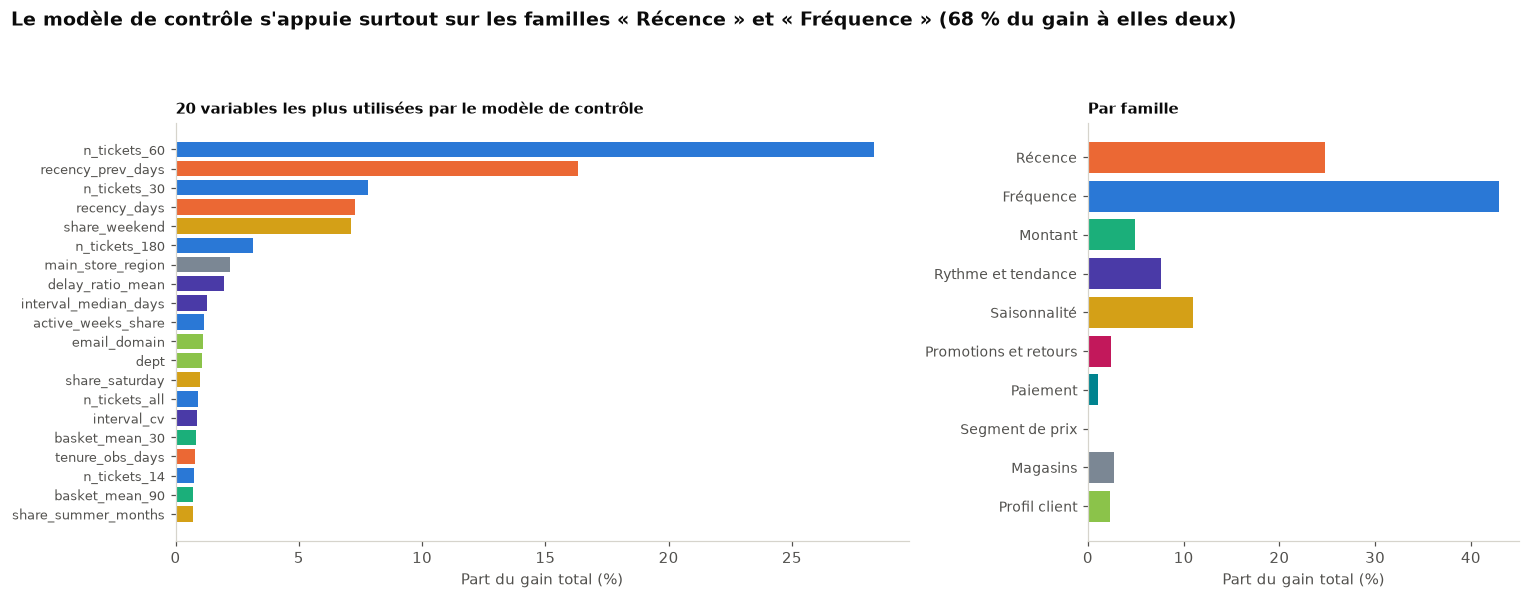

Cohérence train/test du modèle de contrôle : score moyen hors-échantillon du train **0.0770**, score moyen du test **0.0778** ; part du test au-dessus du seuil du top 10 % du train : **10,1 %** (attendu : environ 10 %). L'importance par gain est descriptive (les variables corrélées se partagent le gain) ; l'interprétation propre (SHAP) est au notebook 06.

In [29]:
# Importance du modèle de contrôle (gain), et score moyen train-OOF vs test : simple contrôle de cohérence
Zf_tr, Zf_te = as_lgb(X_fin_tr, cols_so_far), as_lgb(X_fin_te, cols_so_far)
m_full = lgb.LGBMClassifier(**LGB).fit(Zf_tr, yv)
imp = pd.Series(m_full.booster_.feature_importance('gain'), index=cols_so_far)
imp = (imp / imp.sum()).sort_values(ascending=False)
p_te = m_full.predict_proba(Zf_te)[:, 1]
thr90 = np.quantile(oof_full, .9)

fig, axs = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={'width_ratios': [1.7, 1]})
top = imp.head(20)[::-1]
axs[0].barh(top.index, top.values * 100, color=[GCOL[ft.SPEC.loc[col, 'group']] for col in top.index])
axs[0].set_xlabel('Part du gain total (%)'); axs[0].tick_params(axis='y', labelsize=8.5); axs[0].set_title('20 variables les plus utilisées par le modèle de contrôle', fontsize=10, loc='left')
fg = imp.groupby(ft.SPEC.loc[imp.index, 'group']).sum().loc[GROUPS][::-1]
axs[1].barh(fg.index, fg.values * 100, color=[GCOL[g] for g in fg.index]); axs[1].set_xlabel('Part du gain total (%)')
axs[1].set_title('Par famille', fontsize=10, loc='left'); axs[1].tick_params(axis='y', labelsize=9)
done(fig, '02_importance_controle', f"Le modèle de contrôle s'appuie surtout sur les familles « {fg.index[-1]} » et « {fg.index[-2]} » ({pc(fg.values[-1] + fg.values[-2], 0)} du gain à elles deux)")
md(f"Cohérence train/test du modèle de contrôle : score moyen hors-échantillon du train **{oof_full.mean():.4f}**, score moyen du test **{p_te.mean():.4f}** ; part du test au-dessus du seuil du top 10 % du train : **{pc((p_te >= thr90).mean())}** (attendu : environ 10 %). L'importance par gain est descriptive (les variables corrélées se partagent le gain) ; l'interprétation propre (SHAP) est au notebook 06.")

## 9. Sorties : tables de variables, dictionnaire, contrôles finaux

On enregistre `features_train` et `features_test` (variables **retenues** après le retrait des quasi-doublons, plafonnées, avec les jumeaux log), **sans la cible**. Types pour les notebooks de modélisation : `num` = `float64` (avec `NaN` structurels), `bin` = `int8` 0/1, `cat` = chaînes de caractères (à encoder : one-hot N−1 pour les modèles linéaires, type catégoriel pour LightGBM/XGBoost).

In [30]:
# --------------- dictionnaire des variables
def treatment(name):
    parts = []
    r = ft.SPEC.loc[name]
    if r['type'] == 'num' and name in params['caps']:
        lo, hi = params['caps'][name]
        parts.append(f"plafonné au P99,9 du train ({hi:,.4g})" if lo is None else f"borné aux P0,1 et P99,9 du train ({lo:,.4g} ; {hi:,.4g})")
    if name in params['rare_levels']:
        parts.append('modalités rares regroupées en AUTRE')
    if name in log_cols:
        parts.append(f'jumeau {ft.LOG_PREFIX}{name} ajouté (asymétrie élevée)')
    if r['na']:
        parts.append(f"manquant : {r['na']}")
    if r['type'] == 'cat':
        parts.append('à encoder (one-hot N-1 ou type catégoriel)')
    if name in dropped:
        parts.append(f"RETIRÉE : quasi-doublon de {dropped[name][0]} (|rho| = {abs(dropped[name][1]):.3f})")
    return '; '.join(parts) if parts else 'aucun'


dic = ft.SPEC.reset_index()[['name', 'type', 'group', 'description', 'rationale']].copy()
dic['treatment'] = dic['name'].map(treatment)
dic['kept'] = ~dic['name'].isin(list(dropped))
twins = pd.DataFrame({'name': [ft.LOG_PREFIX + col for col in log_cols]})
twins['type'] = 'num'
twins['group'] = twins['name'].map(lambda n: ft.SPEC.loc[n.removeprefix(ft.LOG_PREFIX), 'group'])
twins['description'] = twins['name'].map(lambda n: f"log(1 + {n.removeprefix(ft.LOG_PREFIX)}) (variable déjà plafonnée)")
twins['rationale'] = 'Réduit l\'asymétrie pour les modèles linéaires et le kNN ; inutile pour les arbres (ils ne dépendent que de l\'ordre)'
twins['treatment'] = 'transformation log(1 + x) après plafonnement'
twins['kept'] = ~twins['name'].map(lambda n: n.removeprefix(ft.LOG_PREFIX)).isin(list(dropped))
dic = pd.concat([dic, twins], ignore_index=True)
assert set(dic.loc[dic.kept, 'name']) == set(final_cols) and len(dic) == X_tr_p.shape[1]
dic = dic.set_index('name')
c.save_result('02_feature_dictionary', dic)

# --------------- enregistrement des tables (sans la cible)
assert 'repurchase' not in final_cols and 'y' not in final_cols
c.save_features('train', X_fin_tr)
c.save_features('test', X_fin_te)

# --------------- contrôles finaux sur ce qui est réellement relu par les autres notebooks
f_tr, f_te = c.load_features('train'), c.load_features('test')
assert list(f_tr.columns) == list(f_te.columns) == final_cols
assert f_tr.index.equals(c.load_target().sort_index().index) and f_tr.index.equals(c.get_folds().index)
assert len(f_te) == 40106 and f_te.index.is_unique
assert not np.isinf(f_tr.select_dtypes('float64').to_numpy()).any() and not np.isinf(f_te.select_dtypes('float64').to_numpy()).any()
assert all(f_tr[col].nunique(dropna=False) > 1 for col in f_tr.columns)
assert not f_tr[cat_cols].isna().any().any() and not f_te[cat_cols].isna().any().any()
pd.testing.assert_frame_equal(f_tr, X_fin_tr, check_dtype=False)

kept = dic[dic.kept]
by_group = kept.groupby('group', sort=False).agg(variables=('type', 'size'), num=('type', lambda s: (s == 'num').sum()),
                                                  bin=('type', lambda s: (s == 'bin').sum()), cat=('type', lambda s: (s == 'cat').sum()))
by_group.loc['Total'] = by_group.sum()
display(by_group.astype(int))
c.save_result('02_preprocessing_params', {'cap_quantile': params['cap_q'], 'caps': params['caps'], 'rare_levels': params['rare_levels'],
                                         'log_columns': params['log_cols'], 'duplicates_removed': {k: v[0] for k, v in dropped.items()}})
md(f'''
**Contrôles passés** : mêmes colonnes train/test, index = `id_client` aligné avec la cible et les plis, test = {nf(len(f_te))} clients, aucun `inf`, aucune colonne constante, pas de cible dans la table.
**{f_tr.shape[1]} colonnes** enregistrées dont {int((kept.type == 'num').sum())} numériques (dont {len(log_cols)} jumeaux log), {int((kept.type == 'bin').sum())} binaires, {int((kept.type == 'cat').sum())} qualitatives.
Colonnes qualitatives à encoder : {', '.join(f'`{col}`' for col in cat_cols)}. Colonnes avec `NaN` structurels (à imputer dans le pipeline des modèles linéaires) : {int(f_tr.isna().any().sum())}.
''')

,variables,num,bin,cat
group,,,,
Récence,4,4,0,0
Fréquence,15,15,0,0
Montant,15,15,0,0
Rythme et tendance,20,17,3,0
Saisonnalité,10,9,1,0
Promotions et retours,10,10,0,0
Paiement,6,6,0,0
Segment de prix,2,0,1,1
Magasins,7,4,2,1



**Contrôles passés** : mêmes colonnes train/test, index = `id_client` aligné avec la cible et les plis, test = 40 106 clients, aucun `inf`, aucune colonne constante, pas de cible dans la table.
**100 colonnes** enregistrées dont 81 numériques (dont 31 jumeaux log), 13 binaires, 6 qualitatives.
Colonnes qualitatives à encoder : `price_segment`, `main_store_region`, `civility`, `email_domain`, `email_type`, `dept`. Colonnes avec `NaN` structurels (à imputer dans le pipeline des modèles linéaires) : 50.


## 10. Limites et pistes d'amélioration

**Ce qu'on a vu ou choisi, et ses limites**
- **Un seul mois cible, une seule coupure.** Les variables sont calculées au 1er août 2020, pour prédire août 2020. On ne peut pas apprendre la saisonnalité (un seul août dans les données), et la photo n'est peut-être pas représentative d'un autre mois. Piste : construire les variables à plusieurs dates de coupure sur le passé (multi-coupures) pour multiplier les exemples. *Interdit dans cette première passe, à garder pour la phase d'optimisation.*
- **Historique tronqué à 12 mois** : un client dont le premier ticket est « récent » peut être en réalité un ancien client revenu après 12 mois d'absence ; la variable `tenure_obs_days` est bornée à 366 jours.
- **Fenêtres fixes** (7 à 180 jours) choisies a priori : d'autres fenêtres (3 jours, 21 jours, 120 jours) ou des **décroissances exponentielles** (demi-vie de 14 ou 30 jours) donneraient peut-être un signal plus lisse. Même remarque pour la tendance 90/90.
- **Segment de prix manquant** pour une grande part des clients : gardé comme modalité à part, mais on ne sait pas pourquoi il manque ; l'interroger côté métier (quelles références ne sont pas segmentées ?).
- **Magasins** : seuls les deux premiers chiffres du code sont exploitables ; la fréquentation du magasin est mesurée dans chaque échantillon (train, test), donc un peu plus bruitée sur le test (20 % des clients).
- **Heures de tickets** : les horodatages sont en UTC d'après la documentation, mais leur profil ressemble à des heures locales ; les parts « matin » et « soir » sont donc à lire avec prudence.
- **Plafonds** (tickets et clients) appris sur le train au 99,9e percentile : choix raisonnable (recommandé par le notebook 01) mais non optimisé (volontairement : pas d'optimisation sur la cible à ce stade).
- **La cible est plus étroite que « acheter dans le mois »** : seule une faible part des clients rachète en août 2020 (le taux de rachat est bien inférieur à la reconduction mensuelle observée dans l'historique, cf. notebook 01), et le notebook 01 suggère que la fenêtre réellement observée est courte. **Seul le classement des clients compte** : les probabilités d'un modèle ne sont pas des taux de rachat mensuels et ne doivent pas être lues comme telles (calibration au notebook 06).
- **Rien dans cette table ne dit quel client est joignable** : une part importante de la base n'a pas d'e-mail ; c'est une contrainte de ciblage à traiter au notebook 07.
- **AUC univariée et ablation par familles** : descriptives, elles ne remplacent pas la sélection par les modèles (Lasso, arbres, boosting) faite aux notebooks 03 et 04.

**Pistes non réalisées**
- **Données ouvertes** (slide 85) : à partir du **code INSEE** de la commune du client, ajouter revenu médian, population, densité, part de retraités, type de commune (urbain/rural/littoral), distance au magasin principal ; saisonnalité touristique (communes balnéaires) pour expliquer l'effet « août ». Aucun accès web ici : à faire dans la phase d'amélioration.
- **Calendrier** : jours fériés, vacances scolaires par zone, météo (chaleur, canicule) en août.
- **Panier détaillé** : les données ne contiennent pas les produits ; avec le détail (rayons, produits de marque propre, produits frais), des variables de « profil de panier » seraient possibles.
- **Interactions explicites** (récence × fréquence, retard × tendance) pour les modèles linéaires : les arbres les trouvent seuls.
- **Réduction de dimension** (ACP sur les familles de fréquence/montant, fortement corrélées) pour la régression logistique, et segmentation (notebook 05) réinjectée comme variable.
- **Stabilité dans le temps** : recalculer les distributions de chaque variable mois par mois pour surveiller la dérive après déploiement (slide 89).

In [31]:
sel = auc_df.head(5)
lines = [
    '# Résumé du notebook 02 : feature engineering',
    '',
    '## Chiffres clés',
    f"- **Entrée** : {nf(len(tk_tr))} tickets / {nf(len(cl_tr))} clients (train), {nf(len(tk_te))} tickets / {nf(len(cl_te))} clients (test). Photo au {c.REF_DATE:%d/%m/%Y}, cible = achat en août 2020 (taux {pc(base)}).",
    f"- **{X_tr.shape[1]} variables brutes** construites en {t_tr:.0f} s (même fonction `features.build_features` pour train et test) ; **{f_tr.shape[1]} colonnes** enregistrées après retrait de {len(dropped)} quasi-doublons (|ρ de Spearman| > {THR}) et ajout de {len(log_cols)} jumeaux log.",
    '- Répartition (colonnes enregistrées) : ' + ', '.join(f"{g} {int(by_group.loc[g, 'variables'])}" for g in GROUPS) + '.',
    f"- **Récence seule** (règle, AUC sur le train) : **{rep_rec['auc']:.4f}** ; top 10 % : précision {pc(rep_rec['precision_top10'])}, rappel {pc(rep_rec['recall_top10'])}, lift {rep_rec['lift_top10']:.2f}.",
    f"- **LightGBM de contrôle** (200 arbres, sans réglage, 5 plis communs, toutes variables) : **AUC {rep_full['auc']:.4f}** (écart-type entre plis {rep_full['auc_fold_std']:.4f}) ; top 10 % : précision {pc(rep_full['precision_top10'])}, rappel {pc(rep_full['recall_top10'])}, lift {rep_full['lift_top10']:.2f}. Indication, pas un modèle candidat.",
    '- Meilleures AUC univariées : ' + ', '.join(f"`{k}` {v:.3f}" for k, v in sel['auc_signed'].items()) + ' (définition : AUC d\'une variable seule utilisée comme score ; exploration descriptive).',
    '',
    '## Figures (message)',
]
lines += [f"- `figures/{k}.png` : {v}" for k, v in FIG_MSG.items()]
lines += [
    '',
    '## Décisions méthodologiques',
    "- **Aucune fuite** : variables calculées avec les seuls tickets antérieurs au 01/08/2020 ; cible jamais utilisée pour fabriquer une variable ; plafonds, modalités rares et choix des jumeaux log appris sur le train puis appliqués au test.",
    "- **Achats vs retours** : récence, fréquence et montants sur les tickets d'achat (panier > 0) ; retours décrits à part.",
    "- **Manquants** : compte sans achat dans une fenêtre = 0 ; grandeur non définie (intervalle d'un client à 1 ticket, panier moyen sans ticket) = `NaN` + indicateur (`is_one_shot`, `has_interval_std`) ; attribut qualitatif absent = modalité à part (segment de prix INCONNU, SANS_EMAIL, département INCONNU, civilité ND). Aucun client supprimé.",
    f"- **Valeurs extrêmes** : plafonnement au P99,9 du train (tickets : panier et articles, avant agrégation ; clients : {len(params['caps'])} variables non bornées) ; log(1+x) ajouté (jumeau) pour {len(log_cols)} variables restées très asymétriques (> {ft.SKEW_LOG:.0f}).",
    "- **Modalités rares** (domaine d'e-mail, département, région du magasin) regroupées en AUTRE. One-hot et standardisation laissés aux pipelines des modèles ; discrétisation en classes uniquement pour les graphiques.",
    f"- **Quasi-doublons** (|ρ| > {THR}) : on garde la variable la plus en amont dans le dictionnaire, sans regarder la cible. Fenêtre de 365 jours non construite (≈ historique de 366 jours).",
    '',
    '## Anomalies et points de vigilance',
    f"- {int((X_tr.n_tickets_all == 0).sum())} clients du train n'ont que des retours (aucun achat) : récence `NaN`. Cartes de fidélité postérieures à la date de référence ou sans date valide traitées comme manquantes.",
    f"- La fréquentation du magasin principal est mesurée dans chaque échantillon (part des clients de la base) : plus bruitée sur le test (20 %).",
    f"- La cible ({pc(base)} de rachat) est plus étroite que « acheter dans le mois » : seul le classement compte, les probabilités ne sont pas des taux mensuels (cf. notebook 01).",
    '- Heures des tickets : profil proche d\'heures locales malgré la mention UTC ; parts matin/soir à lire avec prudence.',
    f"- `price_segmentation` est constant au sein d'un client ({pc((nseg == 1).mean())} des clients) et absent pour {pc(D.price_segment_missing.mean())} d'entre eux : traité comme un attribut client (`price_segment`, INCONNU = modalité à part).",
    "- Corrélation brute vs apport marginal : l'écart de rachat entre segments de prix se réduit fortement à fréquence comparable (≥ 8 tickets) ; le mode de paiement discrimine peu dans tous les cas.",
    '',
    '## Limites et pistes',
    "- Une seule coupure (1er août) donc pas de saisonnalité apprenable ; fenêtres fixes ; segment de prix manquant pour une grande part des clients ; AUC univariée et ablation descriptives.",
    "- Pistes (phase d'optimisation) : données ouvertes via le code INSEE (revenu, population, densité, type de commune), calendrier et météo, multi-coupures, décroissances exponentielles, interactions, ACP.",
]
assert len(lines) <= 60, len(lines)
(c.RES / '02_summary.md').write_text('\n'.join(lines) + '\n', encoding='utf-8')
md(f"Résumé écrit dans `results/02_summary.md` ({len(lines)} lignes).")

Résumé écrit dans `results/02_summary.md` (52 lignes).

## Synthèse

In [32]:
md(f'''
On passe de {nf(len(tk_tr))} tickets à une **fiche par client** de **{f_tr.shape[1]} colonnes** regroupées en {len(GROUPS)} familles (récence, fréquence, montant, rythme et tendance, saisonnalité, promotions, paiement, segment de prix, magasins, profil), chacune justifiée par une intuition marketing et reliée au rachat par un graphique. Les manquants et valeurs extrêmes sont traités par des règles explicites apprises sur le train, et la table est contrôlée (colonnes identiques, pas d'infini, distributions train/test comparables, {len(dropped)} quasi-doublon(s) retiré(s)).

Un LightGBM de contrôle sans réglage atteint une AUC de **{rep_full['auc']:.3f}** contre **{rep_rec['auc']:.3f}** pour la récence seule. La suite : **notebook 03** (modèles de référence) et **notebook 04** (arbres et boosting).
''')


On passe de 3 292 994 tickets à une **fiche par client** de **100 colonnes** regroupées en 10 familles (récence, fréquence, montant, rythme et tendance, saisonnalité, promotions, paiement, segment de prix, magasins, profil), chacune justifiée par une intuition marketing et reliée au rachat par un graphique. Les manquants et valeurs extrêmes sont traités par des règles explicites apprises sur le train, et la table est contrôlée (colonnes identiques, pas d'infini, distributions train/test comparables, 17 quasi-doublon(s) retiré(s)).

Un LightGBM de contrôle sans réglage atteint une AUC de **0.878** contre **0.818** pour la récence seule. La suite : **notebook 03** (modèles de référence) et **notebook 04** (arbres et boosting).
